---
# 🛡️ PhalanxSENTINEL &nbsp;  **|** &nbsp;   Dynamic Attack Simulation and Evaluation Module
### **Proposed product**:<br>**PhalanxSENTINEL** — an AI-powered cybersecurity solution intended for robotic warehouse environments  

### Deep Learning Final Project &nbsp; | &nbsp; ITAI 2376 &nbsp; | &nbsp; Fall 2026 <br> Team: Phalanx AI <br> Module developer: Nichelle Graf  
####**Development environment:** Google Colab, Python <br> **Key libraries:** NumPy, pandas, scikit-learn, XGBoost, Matplotlib, ipywidgets, and joblib

---

## 1. Product and Module Overview

 The PhalanxSENTINEL project explores a multi-agent security solution for robotic warehouses, where connected networks, industrial equipment, and robotic activity introduce different cybersecurity risks. The proposed product includes network anomaly detection, vulnerability assessment, and robot integrity monitoring.

**This notebook develops and demonstrates the Dynamic Attack Simulation and Evaluation Module for PhalanxSENTINEL.**

The module generates configurable, synthetic cybersecurity threats and measures how two existing detection models respond under known attack conditions. Its purpose is to support testing and evaluation of the proposed product during development; it is **not** the complete product or an operational warehouse monitoring system.

The module reuses synthetic data generators, feature-engineering procedures, and trained model implementations from **TerraGuard**, Robert and Cesar's separate robotic-warehouse cybersecurity capstone project developed under the team name **TeamPhalanx**. The TerraGuard source repository is a technical dependency, **not** the repository for Phalanx AI's ITAI 2376 final project. The experiments and interactive testing workflow in this notebook are a distinct contribution to the Deep Learning project.

## 2. Problem Statement

A cybersecurity product cannot be assessed solely by whether its detection models run or by their scores on a single predefined test dataset. The models must also be challenged with scenarios in which attacks emerge at different times, intensities, and patterns, and where the actual attack conditions are known.

A network model might miss gradually increasing traffic; a robot-integrity model might identify unauthorized commands but also trigger alerts on unaffected robots. These behaviors matter because missed attacks and false alarms carry different operational consequences.

The **Dynamic Attack Simulation and Evaluation Module** addresses this testing need by generating controlled, time-based scenarios, retaining precise ground-truth attack labels, comparing those labels with model predictions, and presenting interpretable performance evidence.

## 3. Module Objectives

The objectives of this module are to:

1. Generate synthetic baseline network traffic and robot telemetry using the existing capstone data generators.
2. Inject configurable, time-bounded simulated threats, including gradual/sudden DoS activity and unauthorized robot commands.
3. Evaluate existing trained models **without modifying their architectures or training logic**.
4. Maintain attack-active ground-truth labels independently from the features provided to the models.
5. Measure precision, recall, F1 score, false-positive rate, miss rate, and, where applicable, simulated detection delay.
6. Visualize simulated attack periods, detection scores, confusion matrices, and threshold sensitivity.
7. Provide an **interactive interface** through which a user can change parameters and evaluate **newly generated** scenarios without rewriting experiment code.
8. Document limitations and findings that can inform continued development of the proposed PhalanxSENTINEL product.

## 4. Relationship to the Proposed Product

| Proposed PhalanxSENTINEL function | Detection role | Coverage in this module |
|---|---|---|
| **Agent 1 — Network Anomaly Detection** | Identify suspicious network traffic | Simulated gradual and sudden DoS attacks; model evaluation |
| **Agent 2 — Vulnerability Assessment** | Assess and prioritize potential vulnerabilities | **Not evaluated in this notebook** |
| **Agent 3 — Robot Integrity Monitoring** | Identify unauthorized commands and abnormal robot behavior | Simulated T0855 unauthorized commands; model evaluation |

The module is a **development and evaluation tool supporting the broader product**. It does not replace the agents, establish that the full multi-agent system is integrated, or demonstrate autonomous mitigation.

## 5. Evaluation Methodology

**Generate Baseline Data → Configure Attack → Inject Threat → Preserve Ground Truth → Engineer Features → Run Trained Model → Calculate Metrics → Visualize Findings**

**Synthetic data and controlled attacks.** The module creates normal network observations or robot telemetry and injects attacks during explicitly selected time intervals. Reproducible random seeds permit controlled comparisons.

**Ground-truth separation.** The `attack_active` label identifies observations or robot-time windows containing the simulated attack. Ground truth is retained for evaluation and is **excluded from model input features**.

**Model inference.** The generated data is processed by the appropriate existing feature-engineering pipeline, then evaluated with its previously trained classifier. Model training scripts are executed when required for a fresh notebook session; the module does not redesign or tune those models.

**Performance measurement.** Confusion-matrix counts (TP, TN, FP, FN) are used to calculate precision, recall, F1 score, false-positive rate, and miss rate. Timing-based scenarios additionally support simulated detection-delay analysis. Charts distinguish discrete model observations from continuous-time behavior where applicable.

**Dynamic testing.** The interactive interface in Part 4 accepts a new scenario configuration, generates new synthetic observations, evaluates the selected model, and reports updated results. Changing a random seed or attack parameters changes the test input; it does not retrain the model.

## 6. Notebook Organization

| Section | Scope |
|---|---|
| **Part 1 — Agent 1: Network Anomaly Detection** | Steps 1–23: setup, network simulations, DoS comparisons, metrics, and label audit |
| **Part 2 — Agent 3: Robot Integrity Monitoring** | Steps 24–33: robot telemetry, unauthorized-command simulation, evaluation, and threshold sensitivity |
| **Part 3 — Reusable Evaluation Methods** | Steps 34–40: shared evaluation function, validation, plots, cross-agent summary, and environment audit |
| **Part 4 — Interactive Dynamic Attack Testing** | Step 45: configure and execute new synthetic test scenarios through the user interface |

Step numbers reflect the development sequence; some intermediate numbers were retired during notebook cleanup.

## 7. Scope and Limitations

This notebook evaluates **synthetic cybersecurity scenarios** and previously trained detection models; it does not ingest arbitrary external datasets, monitor live warehouse systems, control physical robots, or provide operational incident response. The original model training labels may differ from the module's precise attack-active labels. Network observations and aggregated robot-time windows are distinct evaluation units and should not be ranked as if they were identical tasks.

Detection delay refers to **simulated elapsed time**, not real inference latency. Thresholds explored using the same experimental data are illustrative, not validated production settings. Findings should not be interpreted as commercial deployment readiness.

## 8. Expected Deliverable

A **reproducible, interactive Dynamic Attack Simulation and Evaluation Module** that can produce new controlled test scenarios for Agents 1 and 3, compare the models' predictions with known attack conditions, and communicate meaningful performance evidence for the development of **PhalanxSENTINEL**, the proposed robotic-warehouse cybersecurity product.

---

## Project Attribution and Dependency Boundary

- **Phalanx AI** is the ITAI 2376 Deep Learning project team developing the proposed **PhalanxSENTINEL** product. **TeamPhalanx** is the team behind the separate **TerraGuard** capstone project.
- **Robert Thompson and Cesar Noriega's separate capstone project** provides the existing synthetic generators, feature-engineering pipelines, and detection models used here. Its GitHub repository is an external project dependency, not the Deep Learning team's official repository.
- **Nichelle Graf** developed this notebook's attack simulations, independent ground-truth labeling, evaluation methods, interpretation, and interactive testing interface for the Deep Learning project.

The existing detection-model implementations are used as provided; their limitations are reported as evaluation findings rather than silently corrected in this module.


---
# Part 1 — Network Anomaly Detection (Agent 1)
---
## Environment Setup and Baseline Data Generation

### Purpose

This section prepares the **Dynamic Attack Simulation and Evaluation Module for the proposed PhalanxSENTINEL product** to test network anomaly detection (Agent 1).

The notebook accesses **Robert and Cesar's separate capstone repository** for existing data-generation functions, feature engineering, and model code. That source repository is a technical dependency, not the ITAI 2376 Deep Learning project repository. The notebook retains its own controlled attack scenarios and evaluation labels.

### Initial Workflow

1. Access the TerraGuard capstone source repository in the Colab environment.
2. Verify the repository and import its network data generator.
3. Generate baseline synthetic network observations.
4. Add timing information and independent ground-truth labels.
5. Inject a controlled DoS attack within a defined interval.
6. Visualize the attack to confirm the scenario was generated as intended.

### Expected Outcome

A reproducible network scenario containing normal and attack-active observations, ready for feature engineering and detection evaluation.

**Next:** Step 1 — Initialize the source repository environment.


In [1]:
# ============================================================
# Step 1: Initialize the TerraGuard Source Environment
# ============================================================

import sys
import subprocess
from pathlib import Path

# Existing TerraGuard (TeamPhalanx capstone) repository location.
repo_path = Path("/content/TeamPhalanx-Final-Project")

# Use the original TerraGuard capstone repository URL.
REPO_URL = "https://github.com/w212444150/TeamPhalanx-Final-Project"

# Clone only when the repository is not already present.
if not repo_path.exists():

    subprocess.run(
        ["git", "clone", REPO_URL, str(repo_path)],
        check=True
    )

    print("TeamPhalanx repository cloned successfully.")

else:
    print("TeamPhalanx repository already exists.")

# Ensure project modules can be imported.
if str(repo_path) not in sys.path:
    sys.path.insert(0, str(repo_path))

print(f"Project directory: {repo_path}")
print("Project environment initialized.")

TeamPhalanx repository cloned successfully.
Project directory: /content/TeamPhalanx-Final-Project
Project environment initialized.


In [2]:
# Install the additional dependency required by
# the existing TerraGuard capstone project modules.
%pip install -q optuna

In [3]:
# ===========================================================
# Step 2: Verify that repository was downloaded.
# ===========================================================
import os

repo_path = "/content/TeamPhalanx-Final-Project"

if os.path.isdir(repo_path):
    print("SUCCESS: TeamPhalanx repository found!")
    print("Repository location:", repo_path)
else:
    print("ERROR: Repository folder not found.")

SUCCESS: TeamPhalanx repository found!
Repository location: /content/TeamPhalanx-Final-Project


In [4]:
# ============================================================
# Step 3: Import Existing Synthetic Network Generator
# ============================================================

import os
import sys
import numpy as np
import pandas as pd

# Identify the location of Team Phalanx Final Project repository.
repo_path = "/content/TeamPhalanx-Final-Project"

# Add the repository to Python's search path.
# This allows importing functions from Robert's code.
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

# Import existing function for generating
# normal warehouse network activity.
from collectors.generate_synthetic import _network_normal

print("SUCCESS: network generator imported!")

SUCCESS: network generator imported!


In [ ]:
# ============================================================
# Step 4: Generate and Examine Normal Network Traffic
# ============================================================

# Set a random seed so our results are reproducible.
rng = np.random.default_rng(2376)

# Generate 20 observations of normal warehouse network activity.
# Robert's generator produces one observation per second.
normal_traffic = _network_normal(rng, 20)

# Display the first five observations.
print("NORMAL WAREHOUSE NETWORK TRAFFIC")
display(normal_traffic.head())

# Examine the dataset's structure.
print("\nDataset dimensions (rows, columns):", normal_traffic.shape)
print("\nColumn names:")
print(normal_traffic.columns.tolist())

NORMAL WAREHOUSE NETWORK TRAFFIC


,pkt_count,pkt_size_mean,pkt_size_std,inter_arrival_mean_ms,unique_src_ips,unique_dst_ips,frac_modbus_tcp,frac_ethernet_ip,frac_profinet,frac_http,frac_other
0,611,248.648161,65.513495,1.583211,4,8,0.554904,0.163428,0.239934,0.037803,0.003931
1,503,243.749439,65.241035,1.666601,9,7,0.620727,0.283460,0.049941,0.042938,0.002935
2,661,227.939080,65.096107,1.373261,5,9,0.302881,0.440916,0.031439,0.184791,0.039973
3,622,209.153871,53.368282,1.740354,8,8,0.375495,0.249665,0.277016,0.095862,0.001961
4,585,176.243441,55.953757,1.610441,6,7,0.459120,0.234400,0.202093,0.098809,0.005577



Dataset dimensions (rows, columns): (20, 11)

Column names:
['pkt_count', 'pkt_size_mean', 'pkt_size_std', 'inter_arrival_mean_ms', 'unique_src_ips', 'unique_dst_ips', 'frac_modbus_tcp', 'frac_ethernet_ip', 'frac_profinet', 'frac_http', 'frac_other']


In [ ]:
# ============================================================
# Step 5: Add Time Information to Network Observations
# ============================================================

# Create a separate copy to preserve original data.
timed_traffic = normal_traffic.copy()

# Assign a simulation time to each observation.
# Each row represents one second of network activity.
timed_traffic["elapsed_seconds"] = np.arange(len(timed_traffic))

# Assign a unique identifier to this simulation scenario.
timed_traffic["scenario_id"] = 9001

# All observations are currently normal (no attack).
# 0 = Normal activity, 1 = Attack active.
timed_traffic["attack_active"] = 0

# Display the timing and network activity information.
display(
    timed_traffic[
        ["elapsed_seconds", "scenario_id", "pkt_count", "attack_active"]
    ].head(10)
)

print("Total observations:", len(timed_traffic))
print("Attack-active observations:", timed_traffic["attack_active"].sum())

,elapsed_seconds,scenario_id,pkt_count,attack_active
0,0,9001,611,0
1,1,9001,503,0
2,2,9001,661,0
3,3,9001,622,0
4,4,9001,585,0
5,5,9001,689,0
6,6,9001,569,0
7,7,9001,629,0
8,8,9001,617,0
9,9,9001,627,0


Total observations: 20
Attack-active observations: 0


In [ ]:
# ============================================================
# Step 6: Simulate a Gradually Escalating DoS Attack
# ============================================================

# Preserve the original normal traffic for comparison.
attack_traffic = timed_traffic.copy()

# Define when the attack begins and ends.
attack_start = 5
attack_end = 15

# Define the maximum increase in network traffic.
peak_multiplier = 5.0

# Identify observations within the attack window.
attack_mask = (
    (attack_traffic["elapsed_seconds"] >= attack_start) &
    (attack_traffic["elapsed_seconds"] < attack_end)
)

# Count the observations affected by the attack.
attack_count = attack_mask.sum()

# Create gradually increasing traffic multipliers.
# The first attack observation starts at normal traffic levels.
# The final attack observation reaches 5x normal traffic.
multipliers = np.linspace(1.0, peak_multiplier, attack_count)

# Modify packet counts during the attack window only.
attack_traffic.loc[attack_mask, "pkt_count"] = (
    attack_traffic.loc[attack_mask, "pkt_count"].to_numpy()
    * multipliers
).astype(int)

# Label observations that fall within the attack window.
# These labels are for evaluation, NOT model prediction inputs.
attack_traffic.loc[attack_mask, "attack_active"] = 1

# Display the resulting traffic and attack labels.
display(
    attack_traffic[
        ["elapsed_seconds", "pkt_count", "attack_active"]
    ]
)

# Verify the attack configuration.
print("Total observations:", len(attack_traffic))
print("Attack-active observations:", attack_traffic["attack_active"].sum())
print("Attack begins at second:", attack_start)
print("Attack ends before second:", attack_end)

,elapsed_seconds,pkt_count,attack_active
0,0,611,0
1,1,503,0
2,2,661,0
3,3,622,0
4,4,585,0
5,5,689,1
6,6,821,1
7,7,1188,1
8,8,1439,1
9,9,1741,1


Total observations: 20
Attack-active observations: 10
Attack begins at second: 5
Attack ends before second: 15


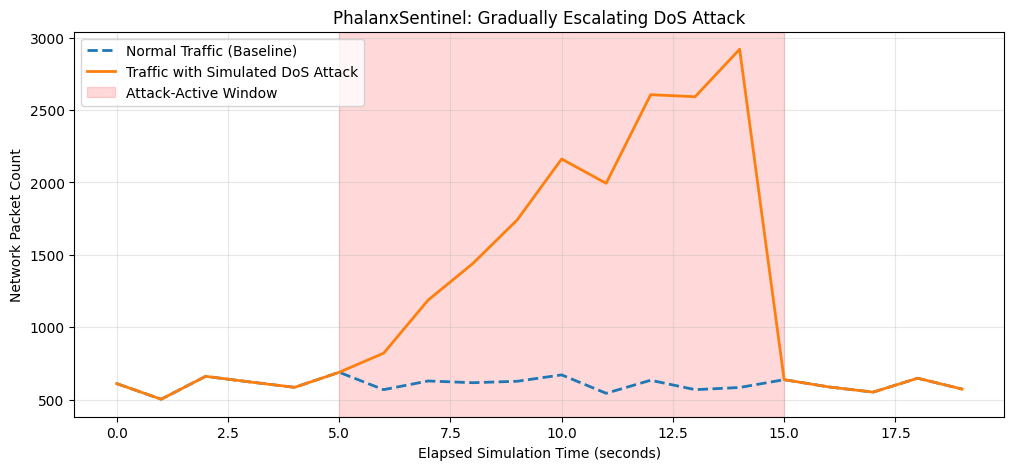

In [ ]:
# ============================================================
# Step 7: Visualize the Simulated DoS Attack
# ============================================================

import matplotlib.pyplot as plt

# Create a figure for the network traffic timeline.
plt.figure(figsize=(12, 5))

# Plot the original normal network traffic as a baseline.
plt.plot(
    timed_traffic["elapsed_seconds"],
    timed_traffic["pkt_count"],
    label="Normal Traffic (Baseline)",
    linestyle="--",
    linewidth=2
)

# Plot the network traffic after introducing the attack.
plt.plot(
    attack_traffic["elapsed_seconds"],
    attack_traffic["pkt_count"],
    label="Traffic with Simulated DoS Attack",
    linewidth=2
)

# Highlight the period during which the attack is active.
plt.axvspan(
    attack_start,
    attack_end,
    color="red",
    alpha=0.15,
    label="Attack-Active Window"
)

# Add descriptive labels and a title.
plt.title("PhalanxSENTINEL: Gradually Escalating DoS Attack")
plt.xlabel("Elapsed Simulation Time (seconds)")
plt.ylabel("Network Packet Count")
plt.legend()
plt.grid(alpha=0.3)

# Display the completed visualization.
plt.show()

In [ ]:
# ============================================================
# Step 8: Prepare Simulated Network Data for Agent 1
# ============================================================

from pipeline.features import features_agent1

# Create a copy of our simulated attack data.
model_input = attack_traffic.copy()

# Existing feature-engineering function expects a timestamp.
# Use a fixed starting time and one-second intervals.
model_input["timestamp"] = pd.date_range(
    start="2026-11-12 00:00:00",
    periods=len(model_input),
    freq="s"
)

# Apply existing feature-engineering function.
engineered_data = features_agent1(model_input)

# Inspect the newly calculated features.
feature_columns = [
    "proto_entropy",
    "size_cv",
    "src_dst_ratio",
    "pkt_count_deviation"
]

display(
    engineered_data[
        ["elapsed_seconds", "pkt_count"] + feature_columns
    ].head(10)
)

print("Feature engineering completed successfully!")
print("Total observations:", len(engineered_data))

,elapsed_seconds,pkt_count,proto_entropy,size_cv,src_dst_ratio,pkt_count_deviation
0,0,611,1.602718,0.263479,0.500000,0.000000
1,1,503,1.378217,0.267656,1.285714,-54.000000
2,2,661,1.835575,0.285586,0.555555,69.333333
3,3,622,1.885392,0.255163,1.000000,22.750000
4,4,585,1.844116,0.317480,0.857143,-11.400000
5,5,689,1.363238,0.282603,0.700000,77.166667
6,6,821,1.940771,0.209596,0.500000,179.285714
7,7,1188,0.861536,0.232929,0.900000,478.000000
8,8,1439,1.421695,0.338442,1.200000,648.000000
9,9,1741,1.324182,0.237069,1.000000,855.000000


Feature engineering completed successfully!
Total observations: 20


In [ ]:
# ============================================================
# Step 9: Validate Input Features for Agent 1
# ============================================================

# Import the exact feature list defined in existing Agent 1.
from agents.agent1_anomaly.phase03_supervised import FEATURE_COLS

# Check whether our simulated dataset contains every
# feature required by Agent 1.
missing_features = [
    col for col in FEATURE_COLS
    if col not in engineered_data.columns
]

# Display the required features.
print("AGENT 1 REQUIRED FEATURES")
print("-" * 40)

for number, feature in enumerate(FEATURE_COLS, start=1):
    print(f"{number:2}. {feature}")

# Validate feature availability.
if missing_features:
    print("\nERROR: Missing features:", missing_features)
else:
    print("\nSUCCESS: All required features are present!")

    # Extract only the features required by Agent 1.
    # The column order must match the model's training inputs.
    X_simulation = engineered_data[FEATURE_COLS].copy()

    print("Model input dimensions:", X_simulation.shape)

    # Verify there are no missing numerical values.
    print(
        "Missing numerical values:",
        X_simulation.isna().sum().sum()
    )

AGENT 1 REQUIRED FEATURES
----------------------------------------
 1. pkt_count
 2. pkt_size_mean
 3. pkt_size_std
 4. inter_arrival_mean_ms
 5. unique_src_ips
 6. unique_dst_ips
 7. frac_modbus_tcp
 8. frac_ethernet_ip
 9. frac_profinet
10. frac_http
11. frac_other
12. proto_entropy
13. size_cv
14. src_dst_ratio
15. pkt_count_deviation

SUCCESS: All required features are present!
Model input dimensions: (20, 15)
Missing numerical values: 0


In [ ]:
# ============================================================
# Step 10: Check for Agent 1's Trained Detection Model
# ============================================================

from pathlib import Path

# Identify the location where Robert saves his trained model.
model_path = Path(repo_path) / "models" / "agent1_xgb.joblib"

# Check whether the trained model file exists.
if model_path.exists():
    print("SUCCESS: Agent 1's trained model is available!")
    print("Model location:", model_path)
else:
    print("Agent 1's trained model has not been generated yet.")
    print("Expected location:", model_path)
    print("We will need to train or obtain the model before testing.")

Agent 1's trained model has not been generated yet.
Expected location: /content/TeamPhalanx-Final-Project/models/agent1_xgb.joblib
We will need to train or obtain the model before testing.


In [ ]:
# ============================================================
# Step 11: Check for Agent 1 Training Data
# ============================================================

from pathlib import Path

# Locate existing processed training datasets.
data_dir = Path(repo_path) / "data" / "processed"

required_files = [
    "agent1_train.parquet",
    "agent1_val.parquet",
    "agent1_test.parquet"
]

print("CHECKING AGENT 1 TRAINING DATA")
print("-" * 40)

# Check whether each required dataset exists.
for filename in required_files:
    file_path = data_dir / filename

    if file_path.exists():
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")

CHECKING AGENT 1 TRAINING DATA
----------------------------------------
MISSING: agent1_train.parquet
MISSING: agent1_val.parquet
MISSING: agent1_test.parquet


In [ ]:
# ============================================================
# Step 12: Generate Agent 1's Training Data
# ============================================================

# Change to existing project directory.
# Sripts expect to find config.yaml in this location.
%cd /content/TeamPhalanx-Final-Project

# Generate synthetic warehouse data.
!python collectors/generate_synthetic.py

# Clean the generated data.
!python pipeline/clean.py

# Calculate features for the detection models.
!python pipeline/features.py

# Split the data into training, validation, and test sets.
!python pipeline/split.py

/content/TeamPhalanx-Final-Project
[generate_synthetic] Wrote 192,000 PLC rows -> data/raw/plc_telemetry.parquet
[generate_synthetic] Wrote 1,728,000 robot rows -> data/raw/robot_states.parquet
[generate_synthetic] Wrote 4,800 network windows -> data/raw/network_flows.parquet
[generate_synthetic] Scenarios: 8 total (4 normal, 4 attack)
[clean] Cleaning complete
[clean] plc     : 192,000 rows kept, 0 dropped
[clean] robot   : 1,728,000 rows kept, 0 dropped
[clean] network : 4,800 rows kept, 0 dropped
[clean] OVERALL: 0 / 1,924,800 dropped (0.0%)
[features] Agent 1 features: 4,800 rows, 21 cols -> agent1_features.parquet
[features] Agent 3 features: 14,400 rows, 12 cols -> agent3_features.parquet
[features] Agent 2 features: 25 advisories, 18 cols -> agent2_features.csv
[split] agent1: train=3,360  val=720  test=720
[split] agent3: train=10,080  val=2,160  test=2,160


In [ ]:
# ============================================================
# Step 13: Train existing Agent 1 Detection Model
# ============================================================

# Run existing Agent 1 training script.
# This trains and evaluates his supervised detection models.
# It does NOT train on this evaluation module's separate attack scenario.

# Run Agent 1's training script with the repository root
# included in Python's module search path.
!PYTHONPATH=/content/TeamPhalanx-Final-Project python agents/agent1_anomaly/phase03_supervised.py

[agent1] train=3360 val=720 test=720
[agent1] attack rate train/test = 0.500 / 0.500
[agent1][rf]  val F1=0.5116 PR-AUC=0.6739
[agent1][xgb] best val PR-AUC = 0.6880
[agent1][xgb] best params = {'n_estimators': 199, 'max_depth': 9, 'learning_rate': 0.01169785807970127, 'subsample': 0.898277841611297, 'colsample_bytree': 0.7572859129174475, 'min_child_weight': 4, 'reg_lambda': 2.0325504681019697}

[agent1][TEST] champion = xgboost
[agent1][TEST] rf  : F1=0.4969  PR-AUC=0.6572  Recall=0.4472
[agent1][TEST] xgb : F1=0.4340  PR-AUC=0.6604  Recall=0.3333
[agent1][TEST] Phase 02 baseline IF : F1=0.2424  PR-AUC=0.5452


In [ ]:
# ============================================================
# Step 14: Verify Trained Agent 1 Model
# ============================================================

from pathlib import Path

# Locate the trained XGBoost model.
model_path = Path(repo_path) / "models" / "agent1_xgb.joblib"

# Confirm that the training process saved the model.
if model_path.exists():
    print("SUCCESS: Agent 1 XGBoost model is ready!")
    print("Model location:", model_path)
    print("Model size:", round(model_path.stat().st_size / 1024, 2), "KB")
else:
    print("ERROR: Trained model file was not found.")

SUCCESS: Agent 1 XGBoost model is ready!
Model location: /content/TeamPhalanx-Final-Project/models/agent1_xgb.joblib
Model size: 632.0 KB


In [ ]:
# ============================================================
# Step 15: Test Agent 1 Against the Module's Simulated DoS Attack
# ============================================================

import joblib

# Load previously trained XGBoost detection model.
agent1_model = joblib.load(model_path)

print("SUCCESS: Agent 1 XGBoost model loaded!")

# Use the 15 network features prepared in Step 9.
# Ground-truth attack labels are NOT included.
X_test = X_simulation.copy()

# Ask Agent 1 to classify each observation.
# 0 = Normal traffic
# 1 = Suspected attack
predictions = agent1_model.predict(X_test)

# Obtain the model's estimated probability for the attack class.
attack_scores = agent1_model.predict_proba(X_test)[:, 1]

# Create a separate DataFrame to store evaluation results.
results = engineered_data[
    ["elapsed_seconds", "pkt_count", "attack_active"]
].copy()

# Add the model's predictions and detection scores.
results["predicted_attack"] = predictions
results["attack_score"] = attack_scores

# Identify whether each prediction matches the actual attack label.
results["correct_prediction"] = (
    results["predicted_attack"] == results["attack_active"]
)

# Display the detection results for all 20 seconds.
print("\nPhalanxSENTINEL - AGENT 1 DETECTION RESULTS")
print("-" * 55)

display(results)

print("\nTotal observations evaluated:", len(results))
print("Total actual attack observations:", results["attack_active"].sum())
print("Total observations flagged by Agent 1:", results["predicted_attack"].sum())

SUCCESS: Agent 1 XGBoost model loaded!

PHALANXSENTINEL - AGENT 1 DETECTION RESULTS
-------------------------------------------------------


,elapsed_seconds,pkt_count,attack_active,predicted_attack,attack_score,correct_prediction
0,0,611,0,0,0.430138,True
1,1,503,0,0,0.432457,True
2,2,661,0,0,0.470761,True
3,3,622,0,0,0.468832,True
4,4,585,0,0,0.453313,True
5,5,689,1,0,0.441854,False
6,6,821,1,1,0.540076,True
7,7,1188,1,0,0.424902,False
8,8,1439,1,0,0.429001,False
9,9,1741,1,0,0.462171,False



Total observations evaluated: 20
Total actual attack observations: 10
Total observations flagged by Agent 1: 5


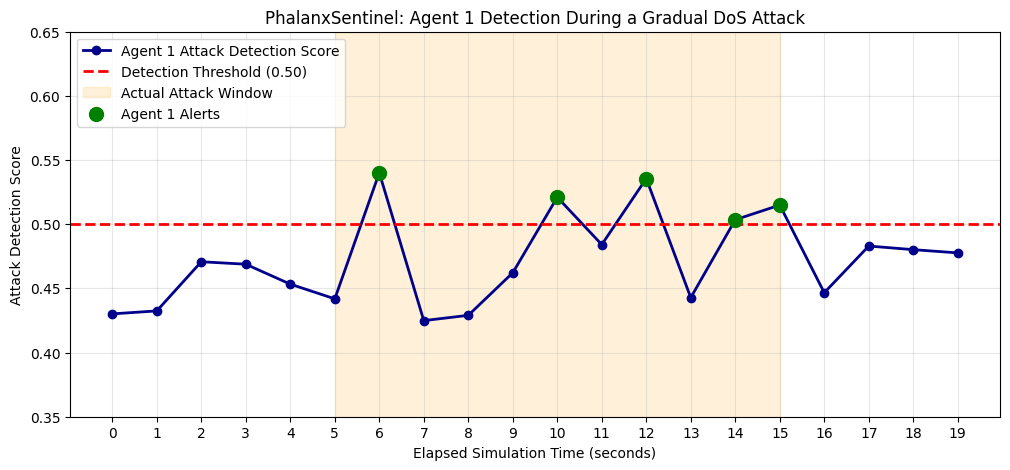

In [ ]:
# ============================================================
# Step 15A: Visualize Agent 1's Detection Performance
# ============================================================
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

# Create a figure to display Agent 1's detection scores.
plt.figure(figsize=(12, 5))

# Plot the model's attack detection score over time.
plt.plot(
    results["elapsed_seconds"],
    results["attack_score"],
    marker="o",
    linewidth=2,
    label="Agent 1 Attack Detection Score",
    color="darkblue"
)

# Draw the model's classification threshold.
# Scores at or above 0.50 are classified as attacks.
plt.axhline(
    y=0.50,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Detection Threshold (0.50)"
)

# Highlight the actual simulated attack window.
plt.axvspan(
    attack_start,
    attack_end,
    color="orange",
    alpha=0.15,
    label="Actual Attack Window"
)

# Highlight observations Agent 1 classified as attacks.
detected = results[results["predicted_attack"] == 1]

plt.scatter(
    detected["elapsed_seconds"],
    detected["attack_score"],
    color="green",
    s=100,
    zorder=5,
    label="Agent 1 Alerts"
)

# Add descriptive labels and formatting.
plt.title("PhalanxSENTINEL: Agent 1 Detection During a Gradual DoS Attack")
plt.xlabel("Elapsed Simulation Time (seconds)")
plt.ylabel("Attack Detection Score")
plt.ylim(0.35, 0.65)
plt.xticks(range(0, 20))
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

# Display the visualization.
plt.show()

In [ ]:
# ============================================================
# Step 16: Evaluate Agent 1 Detection Performance
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Retrieve the ground-truth attack labels from this simulation.
# These labels were NOT provided to Agent 1 during prediction.
y_actual = results["attack_active"]

# Retrieve Agent 1's predicted classifications.
y_predicted = results["predicted_attack"]

# Calculate the confusion matrix.
# tn = True Negatives
# fp = False Positives
# fn = False Negatives
# tp = True Positives
tn, fp, fn, tp = confusion_matrix(
    y_actual,
    y_predicted,
    labels=[0, 1]
).ravel()

# Calculate classification performance.
precision = precision_score(
    y_actual, y_predicted, zero_division=0
)

recall = recall_score(
    y_actual, y_predicted, zero_division=0
)

f1 = f1_score(
    y_actual, y_predicted, zero_division=0
)

# Calculate the false-positive rate.
false_positive_rate = fp / (fp + tn) if (fp + tn) > 0 else 0

# Identify the first detection occurring during an active attack.
detected_attacks = results[
    (results["attack_active"] == 1) &
    (results["predicted_attack"] == 1)
]

# Calculate elapsed simulated time from attack onset to first detection.
if not detected_attacks.empty:
    first_detection = detected_attacks["elapsed_seconds"].min()
    detection_delay = first_detection - attack_start
else:
    first_detection = None
    detection_delay = None

# Display the evaluation results.
print("PhalanxSENTINEL - DETECTION PERFORMANCE")
print("=" * 50)

print(f"True Positives:      {tp}")
print(f"False Negatives:     {fn}")
print(f"False Positives:     {fp}")
print(f"True Negatives:      {tn}")

print("-" * 50)

print(f"Precision:           {precision:.2%}")
print(f"Recall:              {recall:.2%}")
print(f"F1 Score:            {f1:.2%}")
print(f"False Positive Rate: {false_positive_rate:.2%}")

print("-" * 50)

if detection_delay is not None:
    print(f"First Detection:     Second {first_detection}")
    print(f"Detection Delay:     {detection_delay} simulated second(s)")
else:
    print("Detection Delay:     Attack not detected")

PHALANXSENTINEL - DETECTION PERFORMANCE
True Positives:      4
False Negatives:     6
False Positives:     1
True Negatives:      9
--------------------------------------------------
Precision:           80.00%
Recall:              40.00%
F1 Score:            53.33%
False Positive Rate: 10.00%
--------------------------------------------------
First Detection:     Second 6
Detection Delay:     1 simulated second(s)


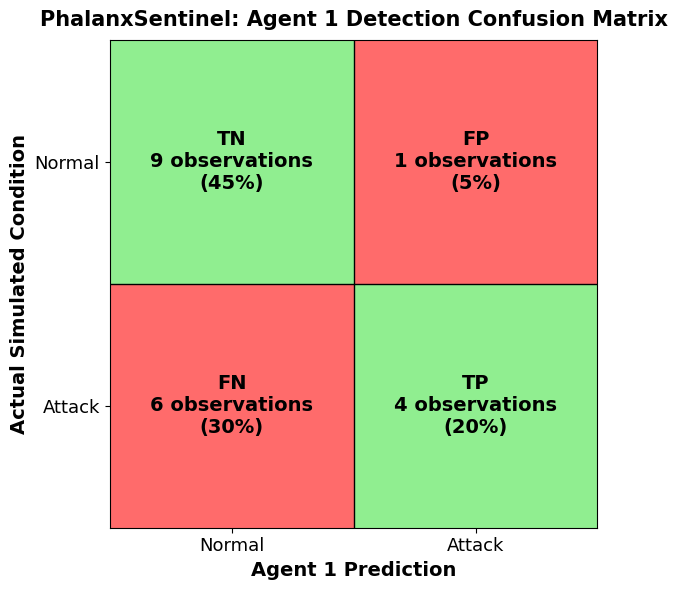

In [ ]:
# ============================================================
# Step 17: Visualize Agent 1's Confusion Matrix
#          Green = Correct | Red = Incorrect
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.metrics import confusion_matrix

# Close previously opened figures to prevent duplicates.
plt.close("all")

# Calculate the confusion matrix using actual and predicted labels.
cm = confusion_matrix(y_actual, y_predicted, labels=[0, 1])

# Create a color matrix:
# 0 = Correct prediction (green)
# 1 = Incorrect prediction (red)
color_matrix = [
    [0, 1],  # Actual Normal: TN (green), FP (red)
    [1, 0]   # Actual Attack: FN (red), TP (green)
]

# Define our custom colors.
cmap = ListedColormap(["#90EE90", "#FF6B6B"])

# Create the visualization.
fig, ax = plt.subplots(figsize=(8, 6))

ax.imshow(color_matrix, cmap=cmap, vmin=0, vmax=1)

# Label the axes.
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Normal", "Attack"], fontsize=13)
ax.set_yticklabels(["Normal", "Attack"], fontsize=13)

ax.set_xlabel("Agent 1 Prediction", fontsize=14, fontweight="bold")
ax.set_ylabel("Actual Simulated Condition", fontsize=14, fontweight="bold")

ax.set_title(
    "PhalanxSENTINEL: Agent 1 Detection Confusion Matrix",
    fontsize=15,
    fontweight="bold",
    pad=10
)

# Add large incident counts and classification labels.
cell_labels = [
    ["TN", "FP"],
    ["FN", "TP"]
]

for i in range(2):
    # Calculate the total number of observations in the dataset.
    total_observations = cm.sum()

    for j in range(2):
        # Calculate each outcome as a percentage of ALL observations.
        percentage = (
        cm[i, j] / total_observations * 100
        if total_observations > 0 else 0
        )

        # Display classification, count, and percentage.
        ax.text(
            j, i,
            f"{cell_labels[i][j]}\n"
            f"{cm[i, j]} observations\n"
            f"({percentage:.0f}%)",
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold",
            color="black"
        )

# Add borders separating the four categories.
ax.set_xticks([0.5], minor=True)
ax.set_yticks([0.5], minor=True)
ax.grid(which="minor", color="black", linewidth=1)
ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout()
plt.show()

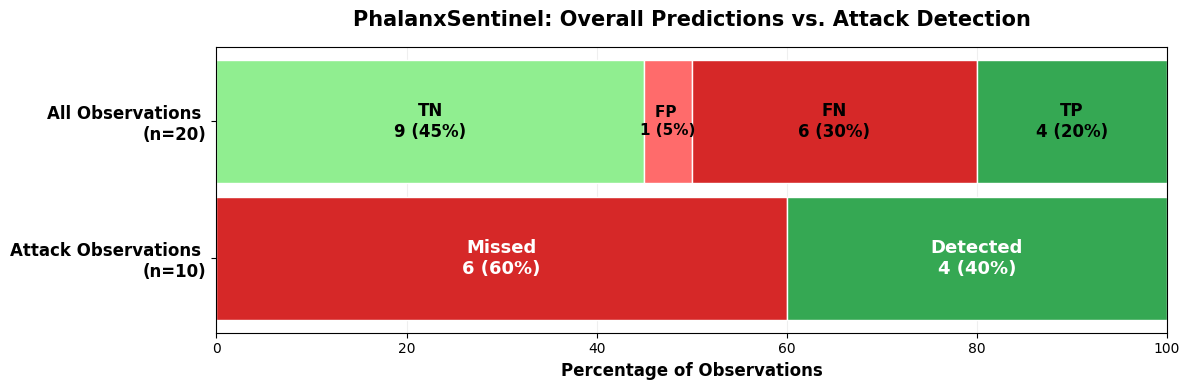

In [ ]:
# ============================================================
# Step 17A: Compare Overall Results vs. Attack Detection
# ============================================================

import matplotlib.pyplot as plt

# Use the confusion matrix calculated in Step 17.
tn, fp, fn, tp = cm.ravel()

# Calculate observation totals.
total = cm.sum()
attack_total = fn + tp

# Calculate percentages for ALL observations.
overall = [
    tn / total * 100,
    fp / total * 100,
    fn / total * 100,
    tp / total * 100
]

# Calculate percentages for ATTACK observations only.
attack_only = [
    fn / attack_total * 100,
    tp / attack_total * 100
]

# Create the chart.
fig, ax = plt.subplots(figsize=(12, 4))

# Define colors for correct and incorrect predictions.
green = "#90EE90"
red = "#FF6B6B"
dark_green = "#35A853"
dark_red = "#D62828"

# ------------------------------------------------------------
# Bar 1: All observations (20 total)
# ------------------------------------------------------------

categories = ["TN", "FP", "FN", "TP"]
colors = [green, red, dark_red, dark_green]
counts = [tn, fp, fn, tp]

left = 0

for category, value, count, color in zip(
    categories, overall, counts, colors
):
    ax.barh(1, value, left=left, color=color,
            edgecolor="white", height=0.9)

    # Place small-segment labels above the bar to avoid overlap.
    if value < 10:
        ax.text(
            left + value / 2,
            1,
            f"{category} \n{count} ({value:.0f}%)",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold"
        )
    else:
        ax.text(
            left + value / 2,
            1,
            f"{category}\n{count} ({value:.0f}%)",
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold"
        )
    left += value
# ------------------------------------------------------------
# Bar 2: Attack-active observations (10 total)
# ------------------------------------------------------------

left = 0

for label, value, count, color in zip(
    ["Missed", "Detected"],
    attack_only,
    [fn, tp],
    [dark_red, dark_green]
):
    ax.barh(0, value, left=left, color=color,
            edgecolor="white", height=0.9)

    ax.text(
        left + value / 2,
        0,
        f"{label}\n{count} ({value:.0f}%)",
        ha="center",
        va="center",
        fontsize=13,
        fontweight="bold",
        color="white"
    )

    left += value

# ------------------------------------------------------------
# Format the visualization.
# ------------------------------------------------------------

ax.set_yticks([0, 1])
ax.set_yticklabels([
    f"Attack Observations \n(n={attack_total})",
    f"All Observations \n(n={total})"
], fontsize=12, fontweight="bold")

ax.set_xlim(0, 100)
ax.set_xlabel("Percentage of Observations", fontsize=12, fontweight="bold")

ax.set_title(
    "PhalanxSENTINEL: Overall Predictions vs. Attack Detection",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Step 18: Generate an Extended Dynamic DoS Attack Scenario
# ============================================================

# Define the parameters for our second experiment.
duration = 120
attack_start_2 = 40
attack_end_2 = 80
peak_multiplier_2 = 5.0

# Use a different random seed to generate new network activity.
rng_2 = np.random.default_rng(2377)

# Generate normal warehouse traffic using generator.
extended_traffic = _network_normal(rng_2, duration)

# Add simulation timing and scenario identification.
extended_traffic["elapsed_seconds"] = np.arange(duration)
extended_traffic["scenario_id"] = 9002

# Create precise observation-level ground-truth labels.
extended_traffic["attack_active"] = 0

# Identify observations occurring during the attack.
attack_mask_2 = (
    (extended_traffic["elapsed_seconds"] >= attack_start_2) &
    (extended_traffic["elapsed_seconds"] < attack_end_2)
)

# Calculate the duration of the active attack.
attack_count_2 = attack_mask_2.sum()

# Generate gradually increasing traffic multipliers.
multipliers_2 = np.linspace(
    1.0,
    peak_multiplier_2,
    attack_count_2
)

# Introduce the simulated DoS attack.
extended_traffic.loc[attack_mask_2, "pkt_count"] = (
    extended_traffic.loc[attack_mask_2, "pkt_count"].to_numpy()
    * multipliers_2
).astype(int)

# Label the observations occurring during the attack.
extended_traffic.loc[attack_mask_2, "attack_active"] = 1

# Add timestamps for feature-engineering pipeline.
extended_traffic["timestamp"] = pd.date_range(
    start="2026-11-12 00:00:00",
    periods=duration,
    freq="s"
)

# Validate the generated scenario.
assert len(extended_traffic) == 120
assert extended_traffic["attack_active"].sum() == 40
assert extended_traffic["pkt_count"].min() > 0

# Display a summary.
print("PhalanxSENTINEL - EXTENDED ATTACK SCENARIO")
print("=" * 50)
print("Total observations:", len(extended_traffic))
print("Normal observations:", (extended_traffic["attack_active"] == 0).sum())
print("Attack observations:", extended_traffic["attack_active"].sum())
print("Attack begins at second:", attack_start_2)
print("Attack ends before second:", attack_end_2)
print("Maximum traffic multiplier:", peak_multiplier_2)

# Display selected observations around the attack boundaries.
display(
    extended_traffic.loc[
        [0, 39, 40, 60, 79, 80, 119],
        ["elapsed_seconds", "pkt_count", "attack_active"]
    ]
)

PHALANXSENTINEL - EXTENDED ATTACK SCENARIO
Total observations: 120
Normal observations: 80
Attack observations: 40
Attack begins at second: 40
Attack ends before second: 80
Maximum traffic multiplier: 5.0


,elapsed_seconds,pkt_count,attack_active
0,0,650,0
39,39,546,0
40,40,594,1
60,60,1842,1
79,79,3295,1
80,80,622,0
119,119,673,0


In [ ]:
# ============================================================
# Step 19: Evaluate Agent 1 Against the Extended DoS Scenario
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 19A: Prepare the extended scenario for Agent 1.
# ------------------------------------------------------------

# Apply existing network feature engineering.
extended_features = features_agent1(extended_traffic.copy())

# Select the same 15 features used to train Agent 1.
# Preserve the original feature order.
X_extended = extended_features[FEATURE_COLS].copy()

# Verify that the model receives valid numerical inputs.
assert X_extended.shape == (120, 15)
assert X_extended.isna().sum().sum() == 0

# ------------------------------------------------------------
# 19B: Run the existing trained model.
# ------------------------------------------------------------

# Predict normal (0) or attack (1) for each observation.
extended_predictions = agent1_model.predict(X_extended)

# Obtain the model's attack-class detection scores.
extended_scores = agent1_model.predict_proba(X_extended)[:, 1]

# Store predictions alongside ground-truth labels.
extended_results = extended_features[
    ["elapsed_seconds", "pkt_count", "attack_active"]
].copy()

extended_results["predicted_attack"] = extended_predictions
extended_results["attack_score"] = extended_scores

# ------------------------------------------------------------
# 19C: Calculate detection performance.
# ------------------------------------------------------------

y_actual_2 = extended_results["attack_active"]
y_predicted_2 = extended_results["predicted_attack"]

# Calculate the confusion matrix.
tn2, fp2, fn2, tp2 = confusion_matrix(
    y_actual_2,
    y_predicted_2,
    labels=[0, 1]
).ravel()

# Calculate performance metrics.
precision_2 = precision_score(
    y_actual_2, y_predicted_2, zero_division=0
)

recall_2 = recall_score(
    y_actual_2, y_predicted_2, zero_division=0
)

f1_2 = f1_score(
    y_actual_2, y_predicted_2, zero_division=0
)

false_positive_rate_2 = (
    fp2 / (fp2 + tn2)
    if (fp2 + tn2) > 0 else 0
)

# Calculate the percentage of attack observations missed.
miss_rate_2 = (
    fn2 / (fn2 + tp2)
    if (fn2 + tp2) > 0 else 0
)

# ------------------------------------------------------------
# 19D: Calculate simulated detection delay.
# ------------------------------------------------------------

# Find alerts occurring during the actual attack window.
detected_attacks_2 = extended_results[
    (extended_results["attack_active"] == 1) &
    (extended_results["predicted_attack"] == 1)
]

if not detected_attacks_2.empty:
    first_detection_2 = detected_attacks_2["elapsed_seconds"].min()
    detection_delay_2 = first_detection_2 - attack_start_2
else:
    first_detection_2 = None
    detection_delay_2 = None

# ------------------------------------------------------------
# 19E: Display evaluation results.
# ------------------------------------------------------------

print("PhalanxSENTINEL - EXTENDED SCENARIO EVALUATION")
print("=" * 55)

print(f"Total Observations:     {len(extended_results)}")
print(f"Attack Observations:    {int(y_actual_2.sum())}")

print("-" * 55)

print(f"True Positives:         {tp2}")
print(f"False Negatives:        {fn2}")
print(f"False Positives:        {fp2}")
print(f"True Negatives:         {tn2}")

print("-" * 55)

print(f"Precision:              {precision_2:.2%}")
print(f"Recall:                 {recall_2:.2%}")
print(f"Miss Rate:              {miss_rate_2:.2%}")
print(f"F1 Score:               {f1_2:.2%}")
print(f"False Positive Rate:    {false_positive_rate_2:.2%}")

print("-" * 55)

if detection_delay_2 is not None:
    print(f"First Detection:        Second {first_detection_2}")
    print(f"Detection Delay:        {detection_delay_2} simulated second(s)")
else:
    print("Detection Delay:        No attack observations detected")

PHALANXSENTINEL - EXTENDED SCENARIO EVALUATION
Total Observations:     120
Attack Observations:    40
-------------------------------------------------------
True Positives:         15
False Negatives:        25
False Positives:        16
True Negatives:         64
-------------------------------------------------------
Precision:              48.39%
Recall:                 37.50%
Miss Rate:              62.50%
F1 Score:               42.25%
False Positive Rate:    20.00%
-------------------------------------------------------
First Detection:        Second 42
Detection Delay:        2 simulated second(s)


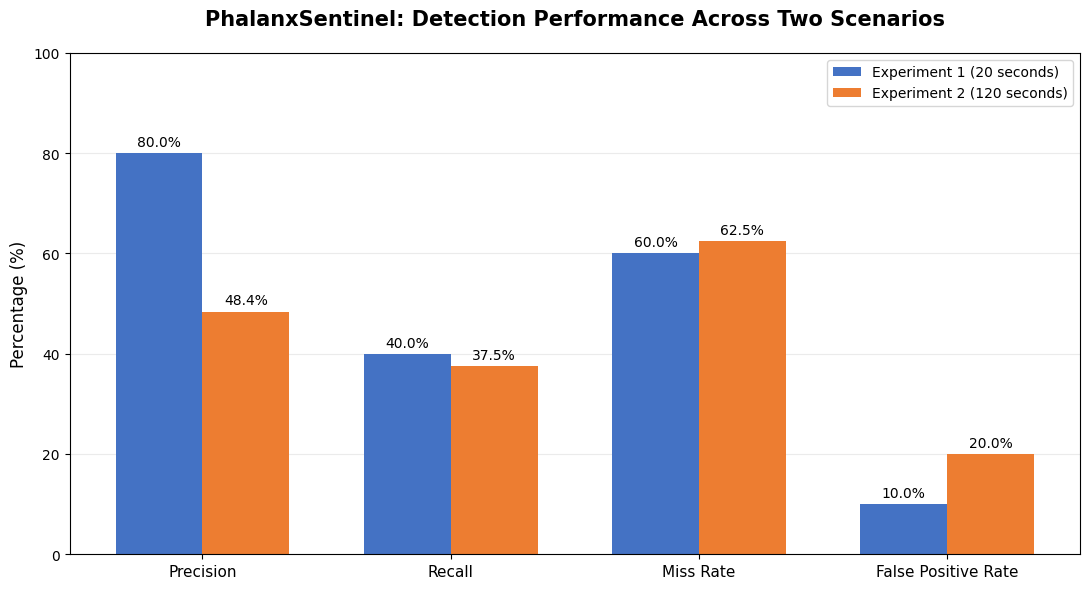

In [ ]:
# ============================================================
# Step 20: Compare Detection Performance Across Experiments
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Close previously opened figures to prevent duplicate charts.
plt.close("all")

# Define the metrics to compare.
metrics = [
    "Precision",
    "Recall",
    "Miss Rate",
    "False Positive Rate"
]

# Performance results from Experiment 1.
experiment_1 = [
    precision * 100,
    recall * 100,
    (fn / (fn + tp)) * 100,
    false_positive_rate * 100
]

# Performance results from Experiment 2.
experiment_2 = [
    precision_2 * 100,
    recall_2 * 100,
    miss_rate_2 * 100,
    false_positive_rate_2 * 100
]

# Set the positions and width of the bars.
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

# Plot both experiments side by side.
bars1 = ax.bar(
    x - width / 2,
    experiment_1,
    width,
    label="Experiment 1 (20 seconds)",
    color="#4472C4"
)

bars2 = ax.bar(
    x + width / 2,
    experiment_2,
    width,
    label="Experiment 2 (120 seconds)",
    color="#ED7D31"
)

# Display percentages above each bar.
ax.bar_label(bars1, fmt="%.1f%%", padding=3, fontsize=10)
ax.bar_label(bars2, fmt="%.1f%%", padding=3, fontsize=10)

# Format the chart.
ax.set_title(
    "PhalanxSENTINEL: Detection Performance Across Two Scenarios",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Percentage (%)", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 100)

ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Step 21: Controlled Comparison - Gradual vs. Sudden DoS
# ============================================================

# Preserve Experiment 2's gradual attack data.
gradual_traffic = extended_traffic.copy()

# Create the sudden-attack scenario from the same baseline.
sudden_traffic = extended_traffic.copy()

# Restore the ORIGINAL normal packet counts.
# Reusing the same random seed recreates the identical baseline.
rng_sudden = np.random.default_rng(2377)
normal_baseline = _network_normal(rng_sudden, 120)

sudden_traffic["pkt_count"] = normal_baseline["pkt_count"].to_numpy()

# Apply the full 5x traffic multiplier immediately
# throughout the attack-active window.
sudden_traffic.loc[attack_mask_2, "pkt_count"] = (
    sudden_traffic.loc[attack_mask_2, "pkt_count"] * peak_multiplier_2
).astype(int)

# The attack labels and timestamps remain unchanged.

# Verify identical conditions outside the attack window.
assert (
    gradual_traffic.loc[~attack_mask_2, "pkt_count"].to_numpy()
    == sudden_traffic.loc[~attack_mask_2, "pkt_count"].to_numpy()
).all()

assert (
    gradual_traffic["attack_active"].to_numpy()
    == sudden_traffic["attack_active"].to_numpy()
).all()

# Display selected observations for comparison.
comparison = pd.DataFrame({
    "Second": gradual_traffic["elapsed_seconds"],
    "Gradual Packet Count": gradual_traffic["pkt_count"],
    "Sudden Packet Count": sudden_traffic["pkt_count"],
    "Attack Active": gradual_traffic["attack_active"]
})

print("PhalanxSENTINEL - CONTROLLED ATTACK COMPARISON")
print("=" * 55)

display(comparison.loc[
    comparison["Second"].isin([39, 40, 45, 60, 79, 80])
])

print("\nSUCCESS: Both scenarios use identical attack windows and baseline traffic.")

PHALANXSENTINEL - CONTROLLED ATTACK COMPARISON


,Second,Gradual Packet Count,Sudden Packet Count,Attack Active
39,39,546,546,0
40,40,594,2970,1
45,45,883,2920,1
60,60,1842,3020,1
79,79,3295,3295,1
80,80,622,622,0



SUCCESS: Both scenarios use identical attack windows and baseline traffic.


In [ ]:
# ============================================================
# Step 22: Compare Agent 1 Detection - Gradual vs. Sudden DoS
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 22A: Prepare sudden attack data for Agent 1.
# ------------------------------------------------------------

# Apply Robert's existing feature-engineering function.
sudden_features = features_agent1(sudden_traffic.copy())

# Select the same 15 features used during model training.
X_sudden = sudden_features[FEATURE_COLS].copy()

# Verify the input dimensions and check for missing values.
assert X_sudden.shape == (120, 15)
assert X_sudden.isna().sum().sum() == 0

# ------------------------------------------------------------
# 22B: Run the trained XGBoost model.
# ------------------------------------------------------------

# Predict whether each observation represents an attack.
sudden_predictions = agent1_model.predict(X_sudden)

# Obtain attack detection scores.
sudden_scores = agent1_model.predict_proba(X_sudden)[:, 1]

# Store predictions alongside actual attack labels.
sudden_results = sudden_features[
    ["elapsed_seconds", "pkt_count", "attack_active"]
].copy()

sudden_results["predicted_attack"] = sudden_predictions
sudden_results["attack_score"] = sudden_scores

# ------------------------------------------------------------
# 22C: Calculate performance metrics.
# ------------------------------------------------------------

y_sudden_actual = sudden_results["attack_active"]
y_sudden_predicted = sudden_results["predicted_attack"]

# Calculate the confusion matrix.
tn_s, fp_s, fn_s, tp_s = confusion_matrix(
    y_sudden_actual,
    y_sudden_predicted,
    labels=[0, 1]
).ravel()

# Calculate classification metrics.
precision_s = precision_score(
    y_sudden_actual, y_sudden_predicted, zero_division=0
)

recall_s = recall_score(
    y_sudden_actual, y_sudden_predicted, zero_division=0
)

f1_s = f1_score(
    y_sudden_actual, y_sudden_predicted, zero_division=0
)

miss_rate_s = fn_s / (fn_s + tp_s) if (fn_s + tp_s) else 0

fpr_s = fp_s / (fp_s + tn_s) if (fp_s + tn_s) else 0

# ------------------------------------------------------------
# 22D: Calculate simulated detection delay.
# ------------------------------------------------------------

# Identify correct alerts during the attack-active window.
sudden_detected = sudden_results[
    (sudden_results["attack_active"] == 1) &
    (sudden_results["predicted_attack"] == 1)
]

if not sudden_detected.empty:
    first_detection_s = sudden_detected["elapsed_seconds"].min()
    detection_delay_s = first_detection_s - attack_start_2
else:
    detection_delay_s = None

# ------------------------------------------------------------
# 22E: Compare both attack patterns.
# ------------------------------------------------------------

comparison_metrics = pd.DataFrame({
    "Metric": [
        "True Positives",
        "False Negatives",
        "False Positives",
        "True Negatives",
        "Precision (%)",
        "Recall (%)",
        "Miss Rate (%)",
        "False Positive Rate (%)",
        "F1 Score (%)",
        "Detection Delay (simulated seconds)"
    ],

    "Gradual Attack": [
        tp2,
        fn2,
        fp2,
        tn2,
        round(precision_2 * 100, 2),
        round(recall_2 * 100, 2),
        round(miss_rate_2 * 100, 2),
        round(false_positive_rate_2 * 100, 2),
        round(f1_2 * 100, 2),
        detection_delay_2
    ],

    "Sudden Attack": [
        tp_s,
        fn_s,
        fp_s,
        tn_s,
        round(precision_s * 100, 2),
        round(recall_s * 100, 2),
        round(miss_rate_s * 100, 2),
        round(fpr_s * 100, 2),
        round(f1_s * 100, 2),
        detection_delay_s
    ]
})

print("PhalanxSENTINEL - GRADUAL VS. SUDDEN DoS")
print("=" * 55)

display(comparison_metrics)

PHALANXSENTINEL - GRADUAL VS. SUDDEN DoS


,Metric,Gradual Attack,Sudden Attack
0,True Positives,15.00,14.00
1,False Negatives,25.00,26.00
2,False Positives,16.00,16.00
3,True Negatives,64.00,64.00
4,Precision (%),48.39,46.67
5,Recall (%),37.50,35.00
6,Miss Rate (%),62.50,65.00
7,False Positive Rate (%),20.00,20.00
8,F1 Score (%),42.25,40.00
9,Detection Delay (simulated seconds),2.00,2.00


In [ ]:
# ============================================================
# Step 23: Audit Agent 1's Training Labels
# ============================================================

import pandas as pd
from pathlib import Path

# Locate processed Agent 1 dataset.
data_path = (
    Path(repo_path)
    / "data"
    / "processed"
    / "agent1_features.parquet"
)

# Load the complete dataset before train/test splitting.
agent1_data = pd.read_parquet(data_path)

print("PhalanxSENTINEL - AGENT 1 LABEL AUDIT")
print("=" * 55)

# Examine the dataset dimensions.
print("Total observations:", len(agent1_data))

# Display the available scenario classifications.
print("\nSCENARIO CLASSIFICATIONS")
print("-" * 55)

scenario_summary = (
    agent1_data
    .groupby(["scenario_id", "attack_class", "is_attack"])
    .size()
    .reset_index(name="observations")
)

display(scenario_summary)

# ------------------------------------------------------------
# Examine the labeling within one attack scenario.
# ------------------------------------------------------------

# Select the first scenario labeled as an attack.
attack_scenarios = agent1_data[
    agent1_data["is_attack"] == 1
]

first_attack_id = attack_scenarios["scenario_id"].iloc[0]

example_scenario = (
    agent1_data[
        agent1_data["scenario_id"] == first_attack_id
    ]
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print("\nEXAMPLE ATTACK SCENARIO")
print("-" * 55)

print("Scenario ID:", first_attack_id)
print(
    "Attack technique:",
    example_scenario["attack_class"].iloc[0]
)

print(
    "Total observations:",
    len(example_scenario)
)

print(
    "Observations labeled as attacks:",
    example_scenario["is_attack"].sum()
)

# Display observations from the beginning, middle,
# and end of the scenario.
sample_positions = [
    0,
    len(example_scenario) // 6,
    len(example_scenario) // 2,
    5 * len(example_scenario) // 6,
    len(example_scenario) - 1
]

display(
    example_scenario.loc[
        sample_positions,
        [
            "timestamp",
            "pkt_count",
            "attack_class",
            "is_attack"
        ]
    ]
)

PHALANXSENTINEL - AGENT 1 LABEL AUDIT
Total observations: 4800

SCENARIO CLASSIFICATIONS
-------------------------------------------------------


,scenario_id,attack_class,is_attack,observations
0,0,normal,0,600
1,1,normal,0,600
2,2,normal,0,600
3,3,normal,0,600
4,4,T0866,1,600
5,5,T0863,1,600
6,6,T0836,1,600
7,7,T0855,1,600



EXAMPLE ATTACK SCENARIO
-------------------------------------------------------
Scenario ID: 4
Attack technique: T0866
Total observations: 600
Observations labeled as attacks: 600


,timestamp,pkt_count,attack_class,is_attack
0,0,666,T0866,1
100,100,678,T0866,1
300,300,562,T0866,1
500,500,573,T0866,1
599,599,575,T0866,1


---
# Part 2 — Dynamic Attack Simulation: Agent 3 (Robot Integrity Monitoring)
---

### Purpose and Transition

Part 1 used this **evaluation module** to test Agent 1 against gradual and sudden DoS scenarios. Those experiments identified both missed attacks and false alarms, illustrating why the proposed **PhalanxSENTINEL product** needs independent testing under controlled conditions.

Part 2 extends the module to **Agent 3 — Robot Integrity Monitoring**. Unlike the network detector, Agent 3 evaluates robot telemetry, including commanded versus actual positions, command sources, and timing.

### Evaluation Objective

Assess whether the existing Agent 3 classifier identifies simulated unauthorized robot commands while distinguishing the attacked robot from unaffected robot activity.

### Evaluation Workflow

1. Generate synthetic baseline robot telemetry using the TerraGuard capstone's data generator.
2. Inject time-bounded unauthorized-command and movement deviations into Robot 0 only.
3. Engineer the seven features expected by the existing detection model.
4. Preserve independent attack labels for each aggregated robot-time window.
5. Evaluate predictions and record correct detections, misses, and false alarms.
6. Visualize detection scores and test threshold sensitivity.

### Scope

This is a **controlled test of a pre-existing model**, not a modification of Agent 3 or a demonstration of a deployed robotic warehouse security system. The synthetic results will inform the **evaluation strategy for PhalanxSENTINEL**.

**Next:** Step 24 — Examine Normal Robot Telemetry.


In [ ]:
# ============================================================
# Step 24: Examine Normal Robot Telemetry for Agent 3
# ============================================================

# Import existing normal robot telemetry generator.
# This reuses simulation logic without modifying code.
from collectors.generate_synthetic import _robot_normal

# Create a reproducible random-number generator.
robot_rng = np.random.default_rng(2376)

# Generate 5 seconds of normal robot activity.
# 20 samples per second = 100 samples per robot joint.
robot_samples = 100

# Generate telemetry for 2 robots, each with 3 joints.
normal_robot = _robot_normal(
    rng=robot_rng,
    n_samples=robot_samples,
    num_robots=2,
    joints=3
)

# Display the first observations.
print("PhalanxSENTINEL - NORMAL ROBOT TELEMETRY")
print("=" * 55)

display(normal_robot.head(10))

# Examine the dataset structure.
print("\nDataset dimensions:", normal_robot.shape)
print("Robot IDs:", normal_robot["robot_id"].unique())
print("Joint IDs:", normal_robot["joint"].unique())

print("\nCommand sources:")
print(normal_robot["cmd_source"].value_counts())

PHALANXSENTINEL - NORMAL ROBOT TELEMETRY


,robot_id,joint,commanded,actual,torque,cmd_source,cmd_interval_ms
0,0,0,-0.646722,0.378289,1.601824,operator_b,49.682421
1,0,0,-0.641302,-0.647933,1.816860,operator_a,51.414069
2,0,0,-0.634880,-0.633810,1.544856,scheduler,49.916631
3,0,0,-0.627465,-0.637407,1.585126,operator_a,48.305150
4,0,0,-0.619070,-0.625013,1.602532,scheduler,50.267815
5,0,0,-0.609707,-0.617650,1.487635,operator_a,50.392321
6,0,0,-0.599391,-0.607406,1.378689,operator_b,48.503239
7,0,0,-0.588139,-0.593472,1.568848,operator_a,51.249146
8,0,0,-0.575967,-0.592759,1.356448,operator_b,52.183578
9,0,0,-0.562895,-0.573098,1.407390,operator_b,51.760837



Dataset dimensions: (600, 7)
Robot IDs: [0 1]
Joint IDs: [0 1 2]

Command sources:
cmd_source
operator_a    271
operator_b    225
scheduler     104
Name: count, dtype: int64


In [ ]:
# ============================================================
# Step 25: Add Timing and Ground-Truth Labels to Robot Data
# ============================================================

# Preserve the original normal robot telemetry.
timed_robot = normal_robot.copy()

# Assign a unique scenario identifier.
timed_robot["scenario_id"] = 9003

# Each robot joint has its own sequence of 100 observations.
# cumcount() starts counting at zero for each robot-joint pair.
timed_robot["sample_number"] = (
    timed_robot.groupby(["robot_id", "joint"]).cumcount()
)

# Convert sample numbers to simulated elapsed time.
# Robot generator operates at 20 samples per second.
timed_robot["timestamp"] = timed_robot["sample_number"] / 20.0

# All observations currently represent normal operation.
timed_robot["attack_class"] = "normal"
timed_robot["is_attack"] = 0

# Separate ground-truth label for this module's evaluation.
timed_robot["attack_active"] = 0

# Display the prepared telemetry.
print("PhalanxSENTINEL - TIMED ROBOT TELEMETRY")
print("=" * 55)

display(
    timed_robot[
        [
            "robot_id",
            "joint",
            "sample_number",
            "timestamp",
            "commanded",
            "actual",
            "attack_active"
        ]
    ].head(10)
)

# Validate the simulation structure.
print("\nTotal observations:", len(timed_robot))
print("Simulation duration:", timed_robot["timestamp"].max() + 0.05)
print("Unique timestamps:", timed_robot["timestamp"].nunique())
print("Attack-active observations:", timed_robot["attack_active"].sum())

PHALANXSENTINEL - TIMED ROBOT TELEMETRY


,robot_id,joint,sample_number,timestamp,commanded,actual,attack_active
0,0,0,0,0.00,-0.646722,0.378289,0
1,0,0,1,0.05,-0.641302,-0.647933,0
2,0,0,2,0.10,-0.634880,-0.633810,0
3,0,0,3,0.15,-0.627465,-0.637407,0
4,0,0,4,0.20,-0.619070,-0.625013,0
5,0,0,5,0.25,-0.609707,-0.617650,0
6,0,0,6,0.30,-0.599391,-0.607406,0
7,0,0,7,0.35,-0.588139,-0.593472,0
8,0,0,8,0.40,-0.575967,-0.592759,0
9,0,0,9,0.45,-0.562895,-0.573098,0



Total observations: 600
Simulation duration: 5.0
Unique timestamps: 100
Attack-active observations: 0


In [ ]:
# ============================================================
# Step 26: Examine Robot Attack Simulation Logic
# ============================================================

import inspect

# Import existing robot attack generator.
from collectors.generate_synthetic import _robot_attack

# Display the function's expected parameters.
print("AGENT 3 - EXISTING ATTACK GENERATOR")
print("=" * 55)

print("\nFunction signature:")
print(inspect.signature(_robot_attack))

# Display the source code to understand how attacks are created.
print("\nORIGINAL ATTACK SIMULATION CODE")
print("-" * 55)

print(inspect.getsource(_robot_attack))

AGENT 3 - EXISTING ATTACK GENERATOR

Function signature:
(rng: 'np.random.Generator', n_samples: 'int', num_robots: 'int', joints: 'int', technique: 'str') -> 'pd.DataFrame'

ORIGINAL ATTACK SIMULATION CODE
-------------------------------------------------------
def _robot_attack(rng: np.random.Generator, n_samples: int, num_robots: int,
                  joints: int, technique: str) -> pd.DataFrame:
    """Robot stream under attack."""
    df = _robot_normal(rng, n_samples, num_robots, joints)
    if technique == "T0855":  # Unauthorized Command Message - spoofed writes
        affected = rng.integers(0, num_robots)
        mask = (df["robot_id"] == affected)
        # Attack affects a middle window of samples
        affected_idx = df[mask].index
        window = affected_idx[len(affected_idx) // 4: len(affected_idx) // 4 * 3]
        # Spoofed command: pushes actual away from commanded, odd cmd_source
        df.loc[window, "actual"] = df.loc[window, "commanded"] + rng.normal(0.08, 

In [ ]:
# ============================================================
# Step 27: Simulate an Unauthorized Robot Command (T0855)
# ============================================================

# Preserve the original normal telemetry.
attack_robot = timed_robot.copy()

# Configure the controlled attack.
target_robot = 0
robot_attack_start = 2.0
robot_attack_end = 4.0

# Use a separate random generator for reproducible attacks.
attack_rng = np.random.default_rng(2376)

# Identify observations belonging to Robot 0
# during the specified attack window.
robot_attack_mask = (
    (attack_robot["robot_id"] == target_robot) &
    (attack_robot["timestamp"] >= robot_attack_start) &
    (attack_robot["timestamp"] < robot_attack_end)
)

# Count the observations affected by the attack.
affected_count = int(robot_attack_mask.sum())

# ------------------------------------------------------------
# Introduce three simulated attack characteristics.
# ------------------------------------------------------------

# 1. Abnormal movement:
#    Actual position deviates from the commanded position.
attack_robot.loc[robot_attack_mask, "actual"] = (
    attack_robot.loc[robot_attack_mask, "commanded"].to_numpy()
    + attack_rng.normal(0.08, 0.02, affected_count)
)

# 2. Unauthorized command source:
#    Replace authorized operators with an unknown source.
attack_robot.loc[robot_attack_mask, "cmd_source"] = "unknown_src"

# 3. Rapid command timing:
#    Reduce command intervals to approximately 5 milliseconds.
attack_robot.loc[robot_attack_mask, "cmd_interval_ms"] = (
    attack_rng.normal(5, 1, affected_count)
)

# ------------------------------------------------------------
# Label the simulated attack.
# These labels are used ONLY for evaluation.
# ------------------------------------------------------------

attack_robot.loc[robot_attack_mask, "attack_active"] = 1
attack_robot.loc[robot_attack_mask, "is_attack"] = 1
attack_robot.loc[robot_attack_mask, "attack_class"] = "T0855"

# ------------------------------------------------------------
# Validate the simulated attack.
# ------------------------------------------------------------

print("PhalanxSENTINEL - ROBOT INTEGRITY ATTACK")
print("=" * 55)

print("Target robot:", target_robot)
print("Attack technique: T0855")
print("Attack window:", robot_attack_start, "to", robot_attack_end)
print("Total observations:", len(attack_robot))
print("Attack-active observations:", attack_robot["attack_active"].sum())

# Confirm the expected number of affected observations.
assert affected_count == 120

# Confirm Robot 1 remains unaffected.
assert (
    attack_robot.loc[attack_robot["robot_id"] == 1]
    .equals(timed_robot.loc[timed_robot["robot_id"] == 1])
)

print("\nSUCCESS: Only Robot 0 was modified.")

# Display selected attack observations.
display(
    attack_robot.loc[
        robot_attack_mask,
        [
            "robot_id",
            "joint",
            "timestamp",
            "commanded",
            "actual",
            "cmd_source",
            "cmd_interval_ms",
            "attack_active"
        ]
    ].head(10)
)

PHALANXSENTINEL - ROBOT INTEGRITY ATTACK
Target robot: 0
Attack technique: T0855
Attack window: 2.0 to 4.0
Total observations: 600
Attack-active observations: 120

SUCCESS: Only Robot 0 was modified.


,robot_id,joint,timestamp,commanded,actual,cmd_source,cmd_interval_ms,attack_active
40,0,0,2.00,0.131223,0.215211,unknown_src,4.517513,1
41,0,0,2.05,0.156629,0.204362,unknown_src,4.589925,1
42,0,0,2.10,0.181790,0.282305,unknown_src,4.286489,1
43,0,0,2.15,0.206667,0.294296,unknown_src,4.595753,1
44,0,0,2.20,0.231221,0.306377,unknown_src,4.074464,1
45,0,0,2.25,0.255414,0.365383,unknown_src,6.035821,1
46,0,0,2.30,0.279207,0.349101,unknown_src,6.430182,1
47,0,0,2.35,0.302565,0.392374,unknown_src,3.670020,1
48,0,0,2.40,0.325449,0.411128,unknown_src,3.831797,1
49,0,0,2.45,0.347824,0.437028,unknown_src,5.090795,1


In [ ]:
# ============================================================
# Step 28: Engineer Features for Agent 3
# ============================================================

from pipeline.features import features_agent3

# ------------------------------------------------------------
# 28A: Apply Robert's existing feature-engineering function.
# ------------------------------------------------------------

# Convert raw robot telemetry into one-second windows.
# Each resulting row represents one robot during one second.
robot_features = features_agent3(attack_robot.copy())

# ------------------------------------------------------------
# 28B: Preserve accurate ground-truth attack labels.
# ------------------------------------------------------------

# The existing feature-engineering function aggregates telemetry
# but does not retain our separate attack_active column.
#
# Create window-level labels from the original simulation.
# A window is labeled as attack-active if at least one
# telemetry observation within that window was attacked.

robot_ground_truth = attack_robot.copy()

# Match Robert's method for creating one-second windows.
robot_ground_truth["win"] = (
    robot_ground_truth["timestamp"].astype(int)
)

# Aggregate our independent attack labels.
window_labels = (
    robot_ground_truth
    .groupby(["scenario_id", "robot_id", "win"])["attack_active"]
    .max()
    .reset_index()
)

# Add the attack-active labels to the engineered dataset.
robot_features = robot_features.merge(
    window_labels,
    on=["scenario_id", "robot_id", "win"],
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 28C: Validate the engineered data.
# ------------------------------------------------------------

# Each robot contributes five one-second windows.
assert len(robot_features) == 10

# Only Robot 0 during seconds 2 and 3 was attacked.
assert robot_features["attack_active"].sum() == 2

# Verify that Robot 1 remains unaffected.
assert (
    robot_features.loc[
        robot_features["robot_id"] == 1,
        "attack_active"
    ] == 0
).all()

# ------------------------------------------------------------
# 28D: Display the results.
# ------------------------------------------------------------

print("PhalanxSENTINEL - AGENT 3 FEATURE ENGINEERING")
print("=" * 55)

print("Total robot windows:", len(robot_features))
print("Attack-active windows:", robot_features["attack_active"].sum())
print(
    "Normal windows:",
    (robot_features["attack_active"] == 0).sum()
)

print("\nROBOT INTEGRITY FEATURES")
print("-" * 55)

display(
    robot_features[
        [
            "robot_id",
            "win",
            "mean_dev",
            "max_dev",
            "torque_var",
            "timing_jitter",
            "nonprimary_src_frac",
            "attack_active"
        ]
    ].sort_values(
        ["robot_id", "win"]
    )
)

print("\nSUCCESS: Robot telemetry prepared for Agent 3!")

PHALANXSENTINEL - AGENT 3 FEATURE ENGINEERING
Total robot windows: 10
Attack-active windows: 2
Normal windows: 8

ROBOT INTEGRITY FEATURES
-------------------------------------------------------


,robot_id,win,mean_dev,max_dev,torque_var,timing_jitter,nonprimary_src_frac,attack_active
0,0,0,0.071570,1.210229,0.264377,1.803704,0.0,0
1,0,1,0.028658,0.075986,0.378025,2.319346,0.0,0
2,0,2,0.081191,0.132121,0.205463,0.948128,1.0,1
3,0,3,0.079622,0.145033,0.411372,0.905951,1.0,1
4,0,4,0.020516,0.065839,0.100843,1.827559,0.0,0
5,1,0,0.019069,0.457008,0.041245,2.067236,0.0,0
6,1,1,0.015695,0.035277,0.095573,1.920658,0.0,0
7,1,2,0.013607,0.033765,0.065883,2.337398,0.0,0
8,1,3,0.013597,0.037425,0.134505,2.099570,0.0,0
9,1,4,0.018974,0.038225,0.079168,1.658560,0.0,0



SUCCESS: Robot telemetry prepared for Agent 3!


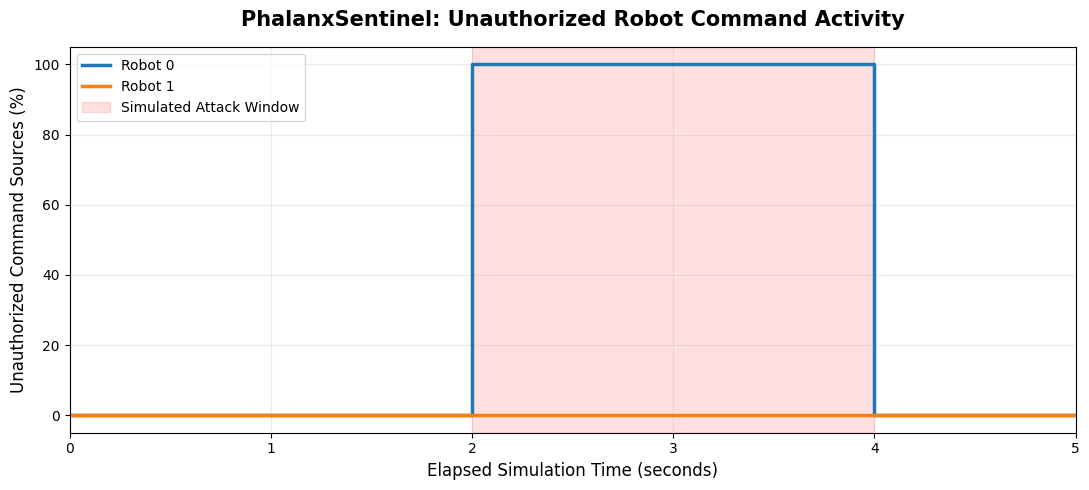

In [ ]:
# ============================================================
# Step 28A: Visualize Unauthorized Robot Command Activity
# ============================================================

import matplotlib.pyplot as plt

# Close any previously open figures.
plt.close("all")

# Create the visualization.
fig, ax = plt.subplots(figsize=(11, 5))

# Plot unauthorized command activity as discrete time windows.
# A step plot accurately represents changes at each second.

for robot_id in sorted(robot_features["robot_id"].unique()):

    robot_data = (
        robot_features[robot_features["robot_id"] == robot_id]
        .sort_values("win")
    )

    # Extend the final value to the end of the last window.
    time_edges = np.append(
        robot_data["win"].to_numpy(),
        robot_data["win"].iloc[-1] + 1
    )

    values = np.append(
        robot_data["nonprimary_src_frac"].to_numpy() * 100,
        robot_data["nonprimary_src_frac"].iloc[-1] * 100
    )

    ax.step(
        time_edges,
        values,
        where="post",
        linewidth=2.5,
        label=f"Robot {robot_id}"
    )
# Highlight the actual attack window.
ax.axvspan(
    robot_attack_start,
    robot_attack_end,
    color="red",
    alpha=0.12,
    label="Simulated Attack Window"
)

# Format the chart.
ax.set_title(
    "PhalanxSENTINEL: Unauthorized Robot Command Activity",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Elapsed Simulation Time (seconds)", fontsize=12)
ax.set_ylabel("Unauthorized Command Sources (%)", fontsize=12)

ax.set_xticks(range(6))
ax.set_xlim(0, 5)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Step 29: Validate Agent 3's Required Model Features
# ============================================================

from pathlib import Path

# These are the seven features defined in Agent 3 supervised training script.
AGENT3_FEATURE_COLS = [
    "mean_dev",
    "max_dev",
    "std_dev",
    "torque_var",
    "timing_jitter",
    "nonprimary_src_frac",
    "cmd_entropy"
]

# ------------------------------------------------------------
# 29A: Validate feature availability.
# ------------------------------------------------------------

# Check that every required feature exists.
missing_features_3 = [
    col for col in AGENT3_FEATURE_COLS
    if col not in robot_features.columns
]

print("PhalanxSENTINEL - AGENT 3 MODEL VALIDATION")
print("=" * 55)

if missing_features_3:
    print("ERROR: Missing features:", missing_features_3)

else:
    print("SUCCESS: All seven required features are present!")

    # Select only the features used during training.
    # Ground-truth attack labels are excluded.
    X_robot = robot_features[AGENT3_FEATURE_COLS].copy()

    print("Model input dimensions:", X_robot.shape)
    print("Missing values:", X_robot.isna().sum().sum())

# ------------------------------------------------------------
# 29B: Check for the existing trained Random Forest model.
# ------------------------------------------------------------

agent3_model_path = (
    Path(repo_path) / "models" / "agent3_rf.joblib"
)

if agent3_model_path.exists():
    print("\nSUCCESS: Agent 3 Random Forest model is available!")
    print("Model location:", agent3_model_path)
else:
    print("\nAgent 3 trained model is not available yet.")
    print("Expected location:", agent3_model_path)

PHALANXSENTINEL - AGENT 3 MODEL VALIDATION
SUCCESS: All seven required features are present!
Model input dimensions: (10, 7)
Missing values: 0

Agent 3 trained model is not available yet.
Expected location: /content/TeamPhalanx-Final-Project/models/agent3_rf.joblib


In [ ]:
# ============================================================
# Step 30: Train Agent 3 Robot Integrity Model
# ============================================================

# Reuse existing training pipeline and datasets.
# Keep this module's evaluation scenarios separate.

!PYTHONPATH=/content/TeamPhalanx-Final-Project python agents/agent3_integrity/phase03_supervised.py

[agent3] train=10080 val=2160 test=2160
[agent3][rf]  val F1=0.7972 PR-AUC=0.8982
[agent3][xgb] val F1=0.7932 PR-AUC=0.8959  best_val_PRAUC=0.8959

[agent3][TEST] champion = random_forest
[agent3][TEST] rf  : F1=0.7902  PR-AUC=0.8982  Recall=0.7778
[agent3][TEST] xgb : F1=0.7834  PR-AUC=0.8966  Recall=0.7685
[agent3][TEST] Phase 02 baseline Mahalanobis : F1=0.3742  PR-AUC=0.7116


In [ ]:
# ============================================================
# Step 31: Evaluate Agent 3 Against Simulated Robot Attacks
# ============================================================

import joblib
from pathlib import Path

# ------------------------------------------------------------
# 31A: Load the trained Robot Integrity Detection model.
# ------------------------------------------------------------

agent3_model_path = (
    Path(repo_path) / "models" / "agent3_rf.joblib"
)

# Verify the model file exists before loading.
assert agent3_model_path.exists(), (
    f"Agent 3 model not found: {agent3_model_path}"
)

agent3_model = joblib.load(agent3_model_path)

print("SUCCESS: Agent 3 Random Forest model loaded!")

# ------------------------------------------------------------
# 31B: Generate predictions.
# ------------------------------------------------------------

# Use the seven features validated in Step 29.
# Ground-truth labels are excluded from model inputs.
robot_predictions = agent3_model.predict(X_robot)

# Obtain attack-class detection scores.
robot_scores = agent3_model.predict_proba(X_robot)[:, 1]

# ------------------------------------------------------------
# 31C: Combine predictions with evaluation labels.
# ------------------------------------------------------------

robot_results = robot_features[
    ["robot_id", "win", "attack_active"]
].copy()

robot_results["predicted_attack"] = robot_predictions
robot_results["attack_score"] = robot_scores

# Identify correctly and incorrectly classified windows.
robot_results["correct_prediction"] = (
    robot_results["predicted_attack"]
    == robot_results["attack_active"]
)

# Sort results chronologically for each robot.
robot_results = robot_results.sort_values(
    ["robot_id", "win"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 31D: Display evaluation results.
# ------------------------------------------------------------

print("\nPhalanxSENTINEL - AGENT 3 DETECTION RESULTS")
print("=" * 55)

display(robot_results)

print("\nTotal robot-time windows:", len(robot_results))
print(
    "Actual attack-active windows:",
    robot_results["attack_active"].sum()
)
print(
    "Windows flagged by Agent 3:",
    robot_results["predicted_attack"].sum()
)

SUCCESS: Agent 3 Random Forest model loaded!

PHALANXSENTINEL - AGENT 3 DETECTION RESULTS


,robot_id,win,attack_active,predicted_attack,attack_score,correct_prediction
0,0,0,0,0,0.363492,True
1,0,1,0,0,0.225984,True
2,0,2,1,1,0.701294,True
3,0,3,1,1,0.894500,True
4,0,4,0,1,0.548389,False
5,1,0,0,1,0.895087,False
6,1,1,0,1,0.743839,False
7,1,2,0,1,0.565402,False
8,1,3,0,1,0.655791,False
9,1,4,0,1,0.694529,False



Total robot-time windows: 10
Actual attack-active windows: 2
Windows flagged by Agent 3: 8


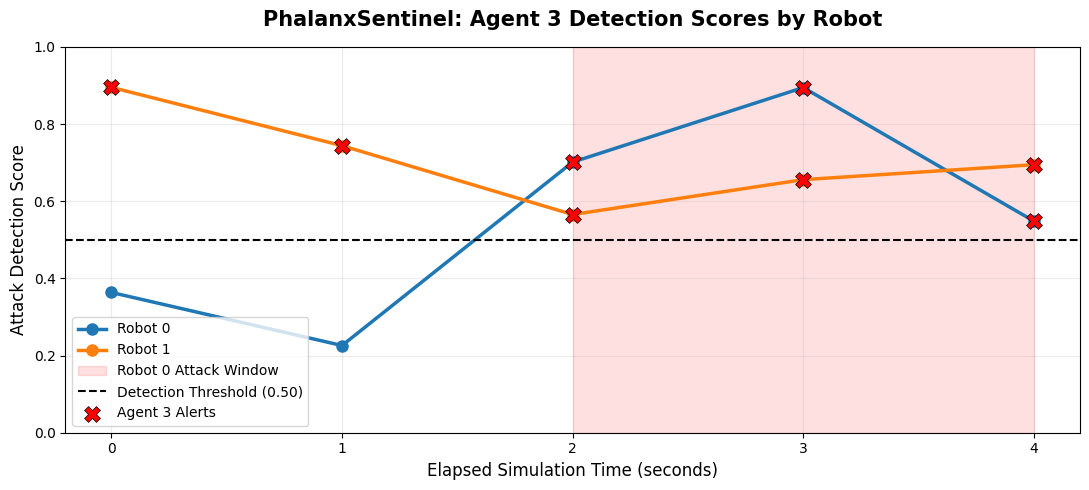

In [ ]:
# ============================================================
# Step 31A: Visualize Agent 3 Detection Scores by Robot
# ============================================================

import matplotlib.pyplot as plt

# Close previously opened figures to avoid duplicate displays.
plt.close("all")

fig, ax = plt.subplots(figsize=(11, 5))

# Plot detection scores for each robot.
for robot_id in sorted(robot_results["robot_id"].unique()):

    robot_data = (
        robot_results[robot_results["robot_id"] == robot_id]
        .sort_values("win")
    )

    ax.plot(
        robot_data["win"],
        robot_data["attack_score"],
        marker="o",
        linewidth=2.5,
        markersize=8,
        label=f"Robot {robot_id}"
    )

# Highlight the simulated attack period.
ax.axvspan(
    robot_attack_start,
    robot_attack_end,
    color="red",
    alpha=0.12,
    label="Robot 0 Attack Window"
)

# Show the classification threshold.
ax.axhline(
    y=0.5,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Detection Threshold (0.50)"
)

# Mark all observations classified as attacks.
alerts = robot_results[
    robot_results["predicted_attack"] == 1
]

ax.scatter(
    alerts["win"],
    alerts["attack_score"],
    marker="X",
    s=130,
    color="red",
    edgecolor="black",
    linewidth=0.5,
    zorder=5,
    label="Agent 3 Alerts"
)

# Format the chart.
ax.set_title(
    "PhalanxSENTINEL: Agent 3 Detection Scores by Robot",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Elapsed Simulation Time (seconds)", fontsize=12)
ax.set_ylabel("Attack Detection Score", fontsize=12)

ax.set_xticks(range(5))
ax.set_ylim(0, 1)

ax.legend(loc="best")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

PHALANXSENTINEL - AGENT 3 DETECTION PERFORMANCE
Total Robot-Time Windows: 10
Attack-Active Windows:    2
-------------------------------------------------------
True Positives:          2
False Negatives:         0
False Positives:         6
True Negatives:          2
-------------------------------------------------------
Precision:               25.00%
Recall:                  100.00%
Miss Rate:               0.00%
F1 Score:                40.00%
False Positive Rate:     75.00%


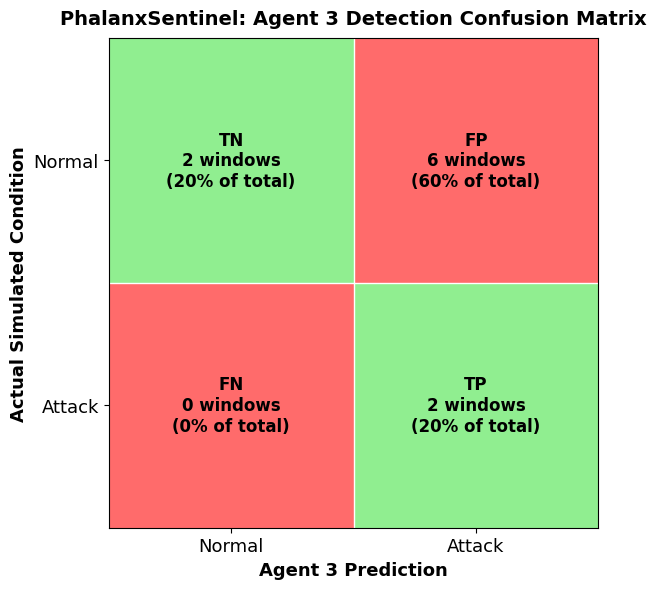

In [ ]:
# ============================================================
# Step 32: Agent 3 Detection Performance and Confusion Matrix
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 32A: Calculate detection metrics.
# ------------------------------------------------------------

# Retrieve actual attack labels and model predictions.
y_robot_actual = robot_results["attack_active"]
y_robot_predicted = robot_results["predicted_attack"]

# Calculate the confusion matrix.
# Rows = Actual conditions; Columns = Model predictions.
cm_robot = confusion_matrix(
    y_robot_actual,
    y_robot_predicted,
    labels=[0, 1]
)

tn_r, fp_r, fn_r, tp_r = cm_robot.ravel()

# Calculate classification performance.
precision_r = precision_score(
    y_robot_actual, y_robot_predicted, zero_division=0
)

recall_r = recall_score(
    y_robot_actual, y_robot_predicted, zero_division=0
)

f1_r = f1_score(
    y_robot_actual, y_robot_predicted, zero_division=0
)

# Calculate the proportion of actual attacks missed.
miss_rate_r = (
    fn_r / (fn_r + tp_r)
    if (fn_r + tp_r) > 0 else 0
)

# Calculate the proportion of normal windows falsely flagged.
false_positive_rate_r = (
    fp_r / (fp_r + tn_r)
    if (fp_r + tn_r) > 0 else 0
)

# ------------------------------------------------------------
# 32B: Display detection performance.
# ------------------------------------------------------------

print("PhalanxSENTINEL - AGENT 3 DETECTION PERFORMANCE")
print("=" * 55)

print(f"Total Robot-Time Windows: {len(robot_results)}")
print(f"Attack-Active Windows:    {int(y_robot_actual.sum())}")

print("-" * 55)

print(f"True Positives:          {tp_r}")
print(f"False Negatives:         {fn_r}")
print(f"False Positives:         {fp_r}")
print(f"True Negatives:          {tn_r}")

print("-" * 55)

print(f"Precision:               {precision_r:.2%}")
print(f"Recall:                  {recall_r:.2%}")
print(f"Miss Rate:               {miss_rate_r:.2%}")
print(f"F1 Score:                {f1_r:.2%}")
print(f"False Positive Rate:     {false_positive_rate_r:.2%}")

# ------------------------------------------------------------
# 32C: Visualize the confusion matrix.
# ------------------------------------------------------------

# Close previously open figures.
plt.close("all")

# Green = Correct prediction; Red = Incorrect prediction.
color_matrix = [
    [0, 1],  # TN, FP
    [1, 0]   # FN, TP
]

cmap = ListedColormap(["#90EE90", "#FF6B6B"])

fig, ax = plt.subplots(figsize=(8, 6))

ax.imshow(color_matrix, cmap=cmap, vmin=0, vmax=1)

# Label the axes.
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Normal", "Attack"], fontsize=13)
ax.set_yticklabels(["Normal", "Attack"], fontsize=13)

ax.set_xlabel(
    "Agent 3 Prediction",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "Actual Simulated Condition",
    fontsize=13,
    fontweight="bold"
)

ax.set_title(
    "PhalanxSENTINEL: Agent 3 Detection Confusion Matrix",
    fontsize=14,
    fontweight="bold",
    pad=10
)

# Add classification labels, counts, and percentages.
# Percentages represent the share of ALL robot-time windows.
cell_labels = [
    ["TN", "FP"],
    ["FN", "TP"]
]

total_windows = cm_robot.sum()

for i in range(2):
    for j in range(2):

        percentage = (
            cm_robot[i, j] / total_windows * 100
            if total_windows > 0 else 0
        )

        ax.text(
            j, i,
            f"{cell_labels[i][j]}\n"
            f"{cm_robot[i, j]} windows\n"
            f"({percentage:.0f}% of total)",
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color="black"
        )

# Add borders separating the four categories.
ax.set_xticks([0.5], minor=True)
ax.set_yticks([0.5], minor=True)

ax.grid(which="minor", color="white", linewidth=1)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

plt.tight_layout()
plt.show()

PHALANXSENTINEL - AGENT 3 THRESHOLD ANALYSIS


,Threshold,Precision (%),Recall (%),False Positive Rate (%),F1 Score (%)
0,0.30,22.22,100.0,87.5,36.36
1,0.35,22.22,100.0,87.5,36.36
2,0.40,25.00,100.0,75.0,40.00
3,0.45,25.00,100.0,75.0,40.00
4,0.50,25.00,100.0,75.0,40.00
5,0.55,28.57,100.0,62.5,44.44
6,0.60,33.33,100.0,50.0,50.00
7,0.65,33.33,100.0,50.0,50.00
8,0.70,50.00,100.0,25.0,66.67
9,0.75,50.00,50.0,12.5,50.00


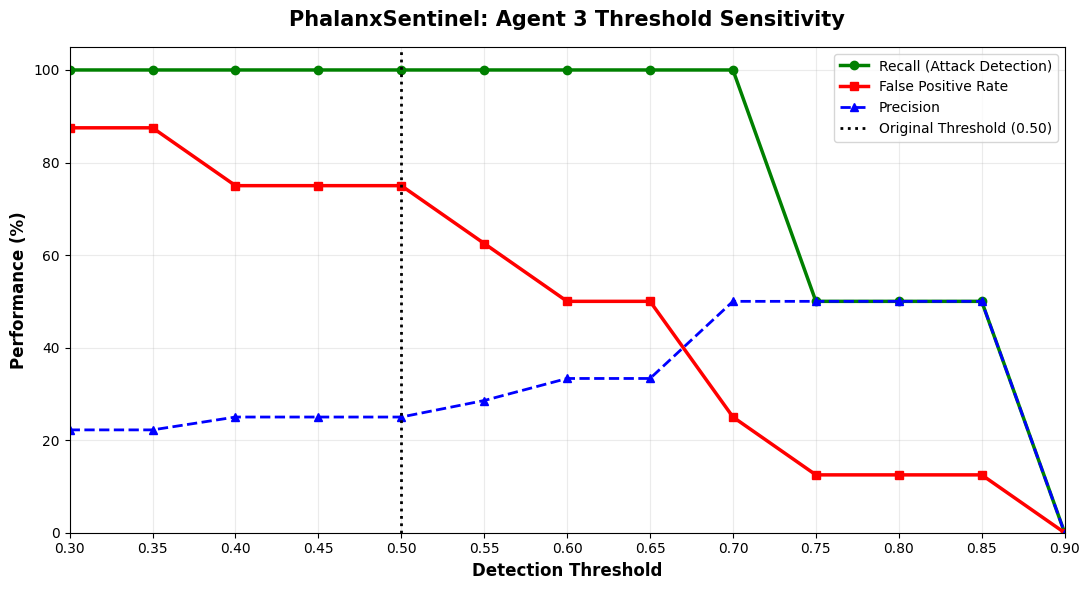

In [ ]:
# ============================================================
# Step 33: Agent 3 Threshold Sensitivity Analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 33A: Define the detection thresholds to evaluate.
# ------------------------------------------------------------

thresholds = np.arange(0.30, 0.91, 0.05)

# Store the evaluation results for each threshold.
threshold_results = []

# ------------------------------------------------------------
# 33B: Evaluate each threshold.
# ------------------------------------------------------------

for threshold in thresholds:

    # Classify observations using the selected threshold.
    # 1 = Attack detected; 0 = Normal.
    threshold_predictions = (
        robot_results["attack_score"] >= threshold
    ).astype(int)

    # Compare predictions against actual attack labels.
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(
        robot_results["attack_active"],
        threshold_predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate detection metrics.
    precision_t = precision_score(
        robot_results["attack_active"],
        threshold_predictions,
        zero_division=0
    )

    recall_t = recall_score(
        robot_results["attack_active"],
        threshold_predictions,
        zero_division=0
    )

    f1_t = f1_score(
        robot_results["attack_active"],
        threshold_predictions,
        zero_division=0
    )

    false_positive_rate_t = (
        fp_t / (fp_t + tn_t)
        if (fp_t + tn_t) > 0 else 0
    )

    # Record results for comparison.
    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision (%)": precision_t * 100,
        "Recall (%)": recall_t * 100,
        "False Positive Rate (%)": false_positive_rate_t * 100,
        "F1 Score (%)": f1_t * 100
    })

# Convert evaluation results into a DataFrame.
threshold_df = pd.DataFrame(threshold_results)

print("PhalanxSENTINEL - AGENT 3 THRESHOLD ANALYSIS")
print("=" * 55)

display(threshold_df.round(2))

# ------------------------------------------------------------
# 33C: Visualize threshold sensitivity.
# ------------------------------------------------------------

plt.close("all")

fig, ax = plt.subplots(figsize=(11, 6))

# Plot recall: percentage of attack windows detected.
ax.plot(
    threshold_df["Threshold"],
    threshold_df["Recall (%)"],
    marker="o",
    linewidth=2.5,
    label="Recall (Attack Detection)",
    color="green"
)

# Plot false-positive rate: percentage of normal windows
# incorrectly classified as attacks.
ax.plot(
    threshold_df["Threshold"],
    threshold_df["False Positive Rate (%)"],
    marker="s",
    linewidth=2.5,
    label="False Positive Rate",
    color="red"
)

# Plot precision: percentage of alerts that were correct.
ax.plot(
    threshold_df["Threshold"],
    threshold_df["Precision (%)"],
    marker="^",
    linewidth=2,
    linestyle="--",
    label="Precision",
    color="blue"
)

# Highlight the original classification threshold.
ax.axvline(
    x=0.50,
    color="black",
    linestyle=":",
    linewidth=2,
    label="Original Threshold (0.50)"
)

# Format the visualization.
ax.set_title(
    "PhalanxSENTINEL: Agent 3 Threshold Sensitivity",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Detection Threshold", fontsize=12, fontweight="bold")
ax.set_ylabel("Performance (%)", fontsize=12, fontweight="bold")

ax.set_ylim(0, 105)
ax.set_xlim(0.30, 0.90)

ax.set_xticks(np.arange(0.30, 0.91, 0.05))

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Agent 3 — Results and Interpretation

### 1. Robot Integrity Simulation

The Dynamic Attack Simulation and Evaluation Module evaluated Agent 3's ability to recognize unauthorized robot commands using a controlled T0855 (Unauthorized Command Message) scenario.

The simulation included two robots with three joints each, operating over five simulated seconds. Unauthorized activity was introduced exclusively into **Robot 0 during seconds 2–4**, while Robot 1 remained unaffected.

The attack modified three telemetry characteristics:

- **Movement deviation:** Actual joint positions were altered relative to commanded positions.
- **Command source:** Authorized sources were replaced with `unknown_src`.
- **Command timing:** Command intervals were reduced to approximately five milliseconds.

The resulting 600 raw telemetry observations were aggregated into 10 one-second robot-time windows. Two windows contained simulated attack activity, while eight represented normal operation.

The unauthorized command activity visualization confirmed that Robot 0 experienced 100% unrecognized command sources during the attack period, while Robot 1 remained at 0%.

### 2. Initial Detection Performance

Agent 3's trained Random Forest model was evaluated using seven engineered robot-integrity features. Ground-truth attack labels were excluded from prediction inputs and retained for independent evaluation.

At the baseline classification threshold of 0.50, the model produced the following results:

| Metric | Result |
|---|---:|
| True Positives | 2 |
| False Negatives | 0 |
| False Positives | 6 |
| True Negatives | 2 |
| Precision | 25.00% |
| Recall | 100.00% |
| Miss Rate | 0.00% |
| False-Positive Rate | 75.00% |
| F1 Score | 40.00% |

The model correctly detected both attack-active windows on Robot 0. However, it also generated six false positives, including alerts for all five windows belonging to the unaffected Robot 1.

These results demonstrate that **successful detection of simulated attack activity does not necessarily indicate reliable discrimination between malicious and normal behavior**.

The confusion matrix and detection-score timeline illustrate this distinction.

### 3. Threshold Sensitivity Analysis

A threshold sensitivity analysis was conducted to examine how different classification thresholds influence Agent 3's predictions.

Thresholds ranging from 0.30 to 0.90 were evaluated using the same model-generated detection scores.

| Performance Metric | Threshold 0.50 | Threshold 0.70 | Threshold 0.75 |
|---|---:|---:|---:|
| Precision | 25.00% | 50.00% | 50.00% |
| Recall | 100.00% | 100.00% | 50.00% |
| False-Positive Rate | 75.00% | 25.00% | 12.50% |

Increasing the threshold from 0.50 to 0.70 reduced false positives from six to two while preserving both correct attack detections.

However, increasing the threshold to 0.75 resulted in one missed attack-active window, reducing recall to 50%.

This demonstrates the trade-off between **detection sensitivity and false-alarm frequency**.

The analysis also illustrates that relatively small threshold adjustments can produce substantial changes in evaluation metrics when the number of attack observations is limited.

### 4. Interpretation and Limitations

The initial experiment demonstrates that this evaluation module can generate controlled robot-integrity attacks, process telemetry through Agent 3's feature-engineering pipeline, evaluate model predictions, and visualize detection performance.

Several limitations must be considered:

1. **Small evaluation sample:** Only 10 robot-time windows were evaluated, including two attack-active windows. The resulting percentages are highly sensitive to individual predictions.
2. **Synthetic data:** The simulation does not establish performance in a physical warehouse or operational robotic system.
3. **Training and evaluation differences:** The model's original training data and labeling methodology may differ from the module's precisely defined attack windows.
4. **Threshold selection:** The apparent improvement at 0.70 was identified using the evaluation data itself. An appropriate operational threshold would require selection using separate validation data and testing against previously unseen scenarios.
5. **Simulation characteristics:** The controlled attack modifies several telemetry features simultaneously. This experiment does not establish which individual features were responsible for the model's predictions.

Consequently, the observed 100% recall and 75% false-positive rate should be interpreted as **results of this specific proof-of-concept experiment**, not as general estimates of Agent 3's detection reliability.

### 5. Key Findings

The Agent 3 evaluation produced three principal findings:

**Finding 1 — Attack recognition:** Agent 3 successfully identified both windows containing simulated unauthorized commands.

**Finding 2 — False-positive behavior:** The model also classified six normal windows as attacks, indicating difficulty distinguishing normal and malicious telemetry under the tested conditions.

**Finding 3 — Threshold sensitivity:** Raising the threshold to 0.70 reduced false positives without sacrificing detection recall in this experiment. However, this result requires independent validation before any threshold recommendation can be made.

### 6. Conclusion

The Agent 3 experiments demonstrate the evaluation module's ability to evaluate a robot-integrity detection model using controlled, time-based attack scenarios and clearly defined ground-truth labels.

The evaluation extends beyond reporting classification accuracy by examining **attack recognition, false-positive behavior, and sensitivity to classification thresholds**.

These findings reinforce the importance of independent model evaluation and transparent interpretation of cybersecurity detection results.

These findings inform the evaluation strategy for the proposed PhalanxSENTINEL product; the subsequent notebook sections consolidate reusable testing methods and provide an interactive simulation interface.

---
# Part 3 — Reusable Evaluation Methods
---

## Consolidating the Evaluation Process

### Purpose

Parts 1 and 2 demonstrated the **Dynamic Attack Simulation and Evaluation Module** with two different detection models used as technical inputs to the proposed **PhalanxSENTINEL product**:

- **Agent 1 — Network Anomaly Detection:** gradual and sudden DoS scenarios.
- **Agent 3 — Robot Integrity Monitoring:** unauthorized-command scenarios.

The agents differ in data, features, algorithms, and evaluation units, but both require model inference, independent ground-truth comparison, classification metrics, and interpretable results.

### Development Objective

Consolidate common operations into reusable Python methods so that new simulated scenarios can be evaluated consistently without rewriting the same metric calculations. The trained detection models and their training logic remain unchanged.

### Evaluation Workflow

**Prepared Scenario → Feature Validation → Model Inference → Classification → Metrics → Report**

### Expected Outcome

Reusable evaluation and visualization methods that support both tested agents and provide the foundation for **Part 4's interactive simulation interface**.

**Next:** Step 34 — Create the Reusable Model Evaluation Function.


In [ ]:
# ============================================================
# Step 34: Create a Reusable Model Evaluation Function
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)


def evaluate_detection_model(
    model,
    data,
    feature_columns,
    threshold=0.50
):
    """
    Evaluate a trained binary cybersecurity detection model.

    Parameters
    ----------
    model : trained classifier
        Existing model with a predict_proba() method.

    data : pandas DataFrame
        Feature-engineered simulation data containing
        the required model features and attack_active labels.

    feature_columns : list
        Ordered list of features expected by the model.

    threshold : float
        Minimum attack-class score required to generate
        an attack prediction. Default is 0.50.

    Returns
    -------
    results : pandas DataFrame
        Ground-truth labels, detection scores, and predictions.

    metrics : dictionary
        Classification counts and performance measures.
    """

    # --------------------------------------------------------
    # 34A: Validate the evaluation inputs.
    # --------------------------------------------------------

    if not 0 <= threshold <= 1:
        raise ValueError("Threshold must be between 0 and 1.")

    required_columns = list(feature_columns) + ["attack_active"]

    missing_columns = [
        column for column in required_columns
        if column not in data.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    # Select only the features expected by the model.
    # Ground-truth labels must not enter model inference.
    X = data[feature_columns].copy()

    if X.isna().any().any():
        raise ValueError("Model input contains missing values.")

    # Verify that ground-truth labels are binary.
    if not data["attack_active"].isin([0, 1]).all():
        raise ValueError(
            "Ground-truth labels must contain only 0 or 1."
        )

    # --------------------------------------------------------
    # 34B: Generate model predictions.
    # --------------------------------------------------------

    # Identify the probability column for the attack class.
    attack_class_index = list(model.classes_).index(1)

    # Obtain attack-class detection scores.
    attack_scores = model.predict_proba(X)[
        :, attack_class_index
    ]

    # Apply the selected classification threshold.
    predictions = (
        attack_scores >= threshold
    ).astype(int)

    # --------------------------------------------------------
    # 34C: Store evaluation results.
    # --------------------------------------------------------

    results = data.copy()

    results["predicted_attack"] = predictions
    results["attack_score"] = attack_scores

    results["correct_prediction"] = (
        results["predicted_attack"]
        == results["attack_active"]
    )

    # --------------------------------------------------------
    # 34D: Calculate classification performance.
    # --------------------------------------------------------

    y_actual = results["attack_active"]
    y_predicted = results["predicted_attack"]

    tn, fp, fn, tp = confusion_matrix(
        y_actual,
        y_predicted,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_actual,
        y_predicted,
        zero_division=0
    )

    recall = recall_score(
        y_actual,
        y_predicted,
        zero_division=0
    )

    f1 = f1_score(
        y_actual,
        y_predicted,
        zero_division=0
    )

    false_positive_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0 else 0
    )

    miss_rate = (
        fn / (fn + tp)
        if (fn + tp) > 0 else 0
    )

    # --------------------------------------------------------
    # 34E: Organize evaluation metrics.
    # --------------------------------------------------------

    metrics = {
        "Threshold": threshold,
        "Total Observations": len(results),
        "Attack Observations": int(y_actual.sum()),
        "True Positives": int(tp),
        "False Negatives": int(fn),
        "False Positives": int(fp),
        "True Negatives": int(tn),
        "Precision": precision,
        "Recall": recall,
        "Miss Rate": miss_rate,
        "False Positive Rate": false_positive_rate,
        "F1 Score": f1
    }

    return results, metrics

In [ ]:
# ============================================================
# Step 35: Validate Reusable Evaluation Against Agent 3
# ============================================================

# ------------------------------------------------------------
# 35A: Run the reusable evaluation function.
# ------------------------------------------------------------

# Evaluate Agent 3 using the existing simulated robot attack.
# The original trained model remains unchanged.
agent3_eval_results, agent3_eval_metrics = evaluate_detection_model(
    model=agent3_model,
    data=robot_features,
    feature_columns=AGENT3_FEATURE_COLS,
    threshold=0.50
)

# ------------------------------------------------------------
# 35B: Compare results with the original evaluation.
# ------------------------------------------------------------

# Verify that the reusable function produces identical
# classifications to the original Step 31 evaluation.
assert np.array_equal(
    agent3_eval_results["predicted_attack"].to_numpy(),
    robot_results["predicted_attack"].to_numpy()
), "ERROR: Predictions do not match the original evaluation."

# Verify the confusion matrix counts from Step 32.
assert agent3_eval_metrics["True Positives"] == tp_r
assert agent3_eval_metrics["False Negatives"] == fn_r
assert agent3_eval_metrics["False Positives"] == fp_r
assert agent3_eval_metrics["True Negatives"] == tn_r

# Verify that the calculated performance metrics match.
assert np.isclose(agent3_eval_metrics["Precision"], precision_r)
assert np.isclose(agent3_eval_metrics["Recall"], recall_r)
assert np.isclose(agent3_eval_metrics["F1 Score"], f1_r)

# ------------------------------------------------------------
# 35C: Display validation results.
# ------------------------------------------------------------

print("PhalanxSENTINEL - REUSABLE EVALUATION VALIDATION")
print("=" * 55)

print("Model: Agent 3 - Robot Integrity Monitoring")
print("Evaluation threshold: 0.50")
print("Total robot-time windows:", len(agent3_eval_results))

print("\nVALIDATION RESULTS")
print("-" * 55)

print("Predictions match original evaluation: YES")
print("Confusion matrix matches: YES")
print("Performance metrics match: YES")

print("\nPERFORMANCE SUMMARY")
print("-" * 55)

print(f"True Positives:       {agent3_eval_metrics['True Positives']}")
print(f"False Negatives:      {agent3_eval_metrics['False Negatives']}")
print(f"False Positives:      {agent3_eval_metrics['False Positives']}")
print(f"True Negatives:       {agent3_eval_metrics['True Negatives']}")

print(f"\nPrecision:            {agent3_eval_metrics['Precision']:.2%}")
print(f"Recall:               {agent3_eval_metrics['Recall']:.2%}")
print(f"Miss Rate:            {agent3_eval_metrics['Miss Rate']:.2%}")
print(f"False Positive Rate:  {agent3_eval_metrics['False Positive Rate']:.2%}")
print(f"F1 Score:             {agent3_eval_metrics['F1 Score']:.2%}")

print("\nSUCCESS: Reusable evaluation function validated!")

PHALANXSENTINEL - REUSABLE EVALUATION VALIDATION
Model: Agent 3 - Robot Integrity Monitoring
Evaluation threshold: 0.50
Total robot-time windows: 10

VALIDATION RESULTS
-------------------------------------------------------
Predictions match original evaluation: YES
Confusion matrix matches: YES
Performance metrics match: YES

PERFORMANCE SUMMARY
-------------------------------------------------------
True Positives:       2
False Negatives:      0
False Positives:      6
True Negatives:       2

Precision:            25.00%
Recall:               100.00%
Miss Rate:            0.00%
False Positive Rate:  75.00%
F1 Score:             40.00%

SUCCESS: Reusable evaluation function validated!


In [ ]:
# ============================================================
# Step 36: Validate Reusable Evaluation Against Agent 1
# ============================================================

# ------------------------------------------------------------
# 36A: Run the reusable evaluation function.
# ------------------------------------------------------------

# Evaluate Agent 1 using the existing 120-second
# gradual DoS scenario and the trained XGBoost model.
agent1_eval_results, agent1_eval_metrics = evaluate_detection_model(
    model=agent1_model,
    data=extended_features,
    feature_columns=FEATURE_COLS,
    threshold=0.50
)

# ------------------------------------------------------------
# 36B: Verify predictions against the original evaluation.
# ------------------------------------------------------------

# Confirm that classifications match those from Step 19.
assert np.array_equal(
    agent1_eval_results["predicted_attack"].to_numpy(),
    extended_results["predicted_attack"].to_numpy()
), "ERROR: Agent 1 predictions do not match."

# Confirm that confusion matrix counts are identical.
assert agent1_eval_metrics["True Positives"] == tp2
assert agent1_eval_metrics["False Negatives"] == fn2
assert agent1_eval_metrics["False Positives"] == fp2
assert agent1_eval_metrics["True Negatives"] == tn2

# Confirm that classification metrics match Step 19.
assert np.isclose(agent1_eval_metrics["Precision"], precision_2)
assert np.isclose(agent1_eval_metrics["Recall"], recall_2)
assert np.isclose(agent1_eval_metrics["F1 Score"], f1_2)

# ------------------------------------------------------------
# 36C: Display validation results.
# ------------------------------------------------------------

print("PhalanxSENTINEL - AGENT 1 EVALUATION VALIDATION")
print("=" * 55)

print("Model: Agent 1 - Network Anomaly Detection")
print("Scenario: 120-second gradual DoS attack")
print("Evaluation threshold: 0.50")

print("\nVALIDATION RESULTS")
print("-" * 55)

print("Predictions match original evaluation: YES")
print("Confusion matrix matches: YES")
print("Performance metrics match: YES")

print("\nPERFORMANCE SUMMARY")
print("-" * 55)

print(f"True Positives:       {agent1_eval_metrics['True Positives']}")
print(f"False Negatives:      {agent1_eval_metrics['False Negatives']}")
print(f"False Positives:      {agent1_eval_metrics['False Positives']}")
print(f"True Negatives:       {agent1_eval_metrics['True Negatives']}")

print(f"\nPrecision:            {agent1_eval_metrics['Precision']:.2%}")
print(f"Recall:               {agent1_eval_metrics['Recall']:.2%}")
print(f"Miss Rate:            {agent1_eval_metrics['Miss Rate']:.2%}")
print(f"False Positive Rate:  {agent1_eval_metrics['False Positive Rate']:.2%}")
print(f"F1 Score:             {agent1_eval_metrics['F1 Score']:.2%}")

print("\nSUCCESS: Agent 1 evaluation function validated!")

PHALANXSENTINEL - AGENT 1 EVALUATION VALIDATION
Model: Agent 1 - Network Anomaly Detection
Scenario: 120-second gradual DoS attack
Evaluation threshold: 0.50

VALIDATION RESULTS
-------------------------------------------------------
Predictions match original evaluation: YES
Confusion matrix matches: YES
Performance metrics match: YES

PERFORMANCE SUMMARY
-------------------------------------------------------
True Positives:       15
False Negatives:      25
False Positives:      16
True Negatives:       64

Precision:            48.39%
Recall:               37.50%
Miss Rate:            62.50%
False Positive Rate:  20.00%
F1 Score:             42.25%

SUCCESS: Agent 1 evaluation function validated!


AGENT 1 — NETWORK ANOMALY DETECTION
Scenario: 120-second gradual DoS attack
-------------------------------------------------------


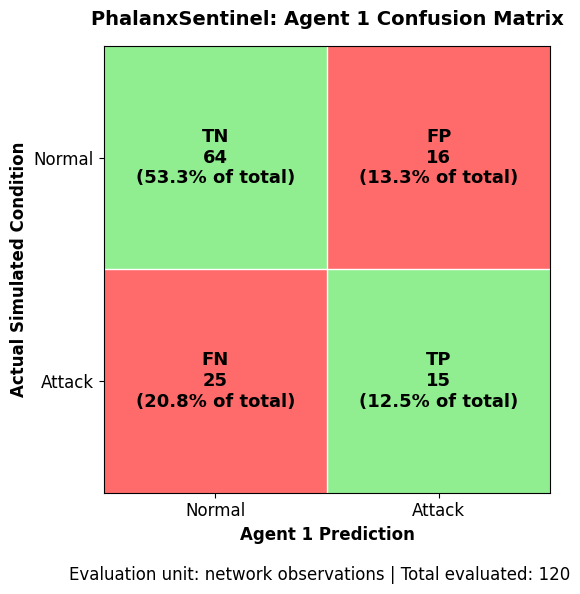

Agent 1 confusion matrix validation: PASSED

AGENT 3 — ROBOT INTEGRITY MONITORING
Scenario: T0855 unauthorized robot commands
-------------------------------------------------------


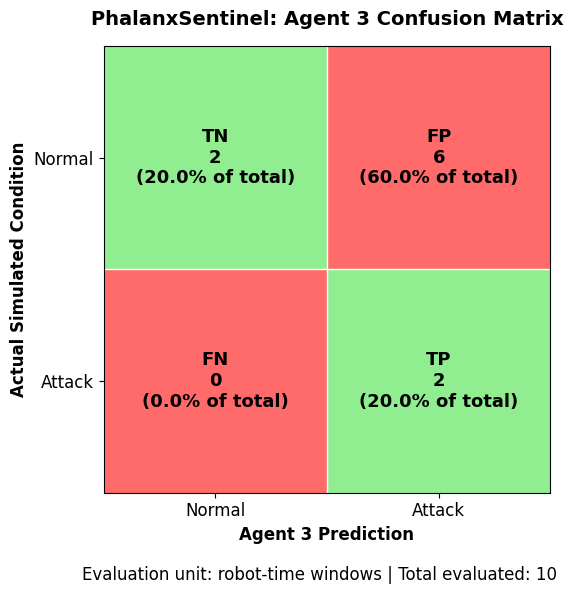

Agent 3 confusion matrix validation: PASSED

SUCCESS: Both confusion matrices validated!


In [ ]:
# ============================================================
# Step 38: Validate and Visualize Both Confusion Matrices
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.metrics import confusion_matrix


# ------------------------------------------------------------
# 38A: Define a compact visualization for validation.
# ------------------------------------------------------------

def display_validated_matrix(results, agent_name, observation_unit):
    """
    Display a readable confusion matrix with classification
    counts and percentages of all evaluated observations.
    """

    cm = confusion_matrix(
        results["attack_active"],
        results["predicted_attack"],
        labels=[0, 1]
    )

    total = cm.sum()

    # Green = Correct predictions; Red = Incorrect predictions.
    color_matrix = [[0, 1], [1, 0]]
    cmap = ListedColormap(["#90EE90", "#FF6B6B"])

    fig, ax = plt.subplots(figsize=(8, 6))

    ax.imshow(color_matrix, cmap=cmap, vmin=0, vmax=1)

    # Classification categories.
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(["Normal", "Attack"], fontsize=12)
    ax.set_yticklabels(["Normal", "Attack"], fontsize=12)

    ax.set_xlabel(
        f"{agent_name} Prediction",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Actual Simulated Condition",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_title(
        f"PhalanxSENTINEL: {agent_name} Confusion Matrix",
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    # Each cell shows its classification, count, and
    # percentage of ALL evaluated observations.
    labels = [["TN", "FP"], ["FN", "TP"]]

    for i in range(2):
        for j in range(2):

            percentage = (
                cm[i, j] / total * 100
                if total > 0 else 0
            )

            ax.text(
                j, i,
                f"{labels[i][j]}\n"
                f"{cm[i, j]}\n"
                f"({percentage:.1f}% of total)",
                ha="center",
                va="center",
                fontsize=13,
                fontweight="bold",
                color="black"
            )

    # Separate the classification cells.
    ax.set_xticks([0.5], minor=True)
    ax.set_yticks([0.5], minor=True)

    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)

    # Identify the evaluation unit outside the matrix.
    fig.text(
        0.5,
        0.025,
        f"Evaluation unit: {observation_unit} | "
        f"Total evaluated: {total}",
        ha="center",
        fontsize=12
    )

    plt.tight_layout(rect=[0, 0.06, 1, 1])
    plt.show()

    return cm


# ------------------------------------------------------------
# 38B: Validate Agent 1 confusion matrix.
# ------------------------------------------------------------

print("AGENT 1 — NETWORK ANOMALY DETECTION")
print("Scenario: 120-second gradual DoS attack")
print("-" * 55)

cm_agent1_reusable = display_validated_matrix(
    results=agent1_eval_results,
    agent_name="Agent 1",
    observation_unit="network observations"
)

assert np.array_equal(
    cm_agent1_reusable,
    np.array([[tn2, fp2], [fn2, tp2]])
), "ERROR: Agent 1 confusion matrix does not match."

print("Agent 1 confusion matrix validation: PASSED")


# ------------------------------------------------------------
# 38C: Validate Agent 3 confusion matrix.
# ------------------------------------------------------------

print("\nAGENT 3 — ROBOT INTEGRITY MONITORING")
print("Scenario: T0855 unauthorized robot commands")
print("-" * 55)

cm_agent3_reusable = display_validated_matrix(
    results=agent3_eval_results,
    agent_name="Agent 3",
    observation_unit="robot-time windows"
)

assert np.array_equal(
    cm_agent3_reusable,
    np.array([[tn_r, fp_r], [fn_r, tp_r]])
), "ERROR: Agent 3 confusion matrix does not match."

print("Agent 3 confusion matrix validation: PASSED")

print("\nSUCCESS: Both confusion matrices validated!")

### Cross-Agent Evaluation: Interpretation Considerations

Although this Dynamic Attack Simulation and Evaluation Module applies a consistent methodology to Agent 1 and Agent 3, their performance metrics should **not be interpreted as a direct comparison of model superiority**.

The two agents differ in several important ways:

- **Detection objectives:** Agent 1 identifies network anomalies associated with denial-of-service (DoS) attacks, while Agent 3 identifies robot-integrity violations associated with unauthorized commands.
- **Input features:** Agent 1 evaluates 15 network-related features using an XGBoost classifier, whereas Agent 3 evaluates seven robot-integrity features using a Random Forest classifier.
- **Evaluation units:** Agent 1 was evaluated using 120 individual network observations, while Agent 3 was evaluated using 10 aggregated robot-time windows.
- **Attack scenarios:** The experiments simulate different threats, durations, and behavioral characteristics.
- **Sample sizes:** Agent 3's substantially smaller evaluation dataset makes its performance metrics particularly sensitive to individual predictions.

Consequently, differences in precision, recall, F1 score, and false-positive rates do not establish that one agent is inherently more effective than the other.

**The purpose of the cross-agent comparison is to demonstrate that the evaluation module can apply standardized procedures to distinct detection functions proposed for PhalanxSENTINEL.**

By maintaining consistent metric definitions, ground-truth validation, and visualization methods, this module provides a reusable framework for identifying detection strengths, limitations, and potential areas for further investigation.

The results represent performance under the specific simulated conditions tested, rather than generalized estimates of operational cybersecurity effectiveness.

In [ ]:
# ============================================================
# Step 39: Cross-Agent Performance Summary
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 39A: Consolidate validated evaluation metrics.
# ------------------------------------------------------------

# Use the results produced by the reusable evaluation
# function in Steps 35 and 36.

agent_comparison = pd.DataFrame({
    "Metric": [
        "Detection Model",
        "Threat Scenario",
        "Evaluation Unit",
        "Total Evaluated",
        "Attack-Active Units",
        "True Positives",
        "False Negatives",
        "False Positives",
        "True Negatives",
        "Precision (%)",
        "Recall (%)",
        "Miss Rate (%)",
        "False Positive Rate (%)",
        "F1 Score (%)"
    ],

    "Agent 1 — Network": [
        "XGBoost",
        "Gradual DoS",
        "Network observations",
        agent1_eval_metrics["Total Observations"],
        agent1_eval_metrics["Attack Observations"],
        agent1_eval_metrics["True Positives"],
        agent1_eval_metrics["False Negatives"],
        agent1_eval_metrics["False Positives"],
        agent1_eval_metrics["True Negatives"],
        agent1_eval_metrics["Precision"] * 100,
        agent1_eval_metrics["Recall"] * 100,
        agent1_eval_metrics["Miss Rate"] * 100,
        agent1_eval_metrics["False Positive Rate"] * 100,
        agent1_eval_metrics["F1 Score"] * 100
    ],

    "Agent 3 — Robot Integrity": [
        "Random Forest",
        "T0855 Unauthorized Commands",
        "Robot-time windows",
        agent3_eval_metrics["Total Observations"],
        agent3_eval_metrics["Attack Observations"],
        agent3_eval_metrics["True Positives"],
        agent3_eval_metrics["False Negatives"],
        agent3_eval_metrics["False Positives"],
        agent3_eval_metrics["True Negatives"],
        agent3_eval_metrics["Precision"] * 100,
        agent3_eval_metrics["Recall"] * 100,
        agent3_eval_metrics["Miss Rate"] * 100,
        agent3_eval_metrics["False Positive Rate"] * 100,
        agent3_eval_metrics["F1 Score"] * 100
    ]
})

# ------------------------------------------------------------
# 39B: Format the summary for readability.
# ------------------------------------------------------------

# Preserve counts as integers and display performance
# percentages to two decimal places.

percentage_rows = [
    "Precision (%)",
    "Recall (%)",
    "Miss Rate (%)",
    "False Positive Rate (%)",
    "F1 Score (%)"
]

count_rows = [
    "Total Evaluated",
    "Attack-Active Units",
    "True Positives",
    "False Negatives",
    "False Positives",
    "True Negatives"
]

display_comparison = agent_comparison.copy()

for column in ["Agent 1 — Network", "Agent 3 — Robot Integrity"]:

    for index in display_comparison.index:

        metric = display_comparison.loc[index, "Metric"]
        value = display_comparison.loc[index, column]

        if metric in percentage_rows:
            display_comparison.loc[index, column] = f"{value:.2f}%"

        elif metric in count_rows:
            display_comparison.loc[index, column] = str(int(value))

# ------------------------------------------------------------
# 39C: Display the consolidated evaluation results.
# ------------------------------------------------------------

print("PhalanxSENTINEL — CROSS-AGENT EVALUATION SUMMARY")
print("=" * 65)

display(display_comparison.set_index("Metric"))

# ------------------------------------------------------------
# 39D: Validate the consolidated counts.
# ------------------------------------------------------------

# Confirm that each agent's classification counts account
# for every evaluated observation or robot-time window.

for metrics, agent_name in [
    (agent1_eval_metrics, "Agent 1"),
    (agent3_eval_metrics, "Agent 3")
]:

    classification_total = (
        metrics["True Positives"]
        + metrics["False Negatives"]
        + metrics["False Positives"]
        + metrics["True Negatives"]
    )

    assert classification_total == metrics["Total Observations"], (
        f"{agent_name}: Classification counts do not "
        "match total evaluated units."
    )

print("\nVALIDATION: All classification totals match.")
print("SUCCESS: Cross-agent evaluation summary generated.")

PHALANXSENTINEL — CROSS-AGENT EVALUATION SUMMARY


,Agent 1 — Network,Agent 3 — Robot Integrity
Metric,,
Detection Model,XGBoost,Random Forest
Threat Scenario,Gradual DoS,T0855 Unauthorized Commands
Evaluation Unit,Network observations,Robot-time windows
Total Evaluated,120,10
Attack-Active Units,40,2
True Positives,15,2
False Negatives,25,0
False Positives,16,6
True Negatives,64,2



VALIDATION: All classification totals match.
SUCCESS: Cross-agent evaluation summary generated.


In [ ]:
# ============================================================
# Step 40: Reproducibility Audit
# Verify Environment, Dependencies, and Project Files
# ============================================================

import sys
import importlib
import importlib.metadata
from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# 40A: Verify the TerraGuard source repository.
# ------------------------------------------------------------

print("PhalanxSENTINEL — REPRODUCIBILITY AUDIT")
print("=" * 65)

project_root = Path("/content/TeamPhalanx-Final-Project")

print("\n1. PROJECT REPOSITORY")
print("-" * 65)

print(f"Repository location: {project_root}")
print(f"Repository exists:   {project_root.is_dir()}")

# ------------------------------------------------------------
# 40B: Verify required project files.
# ------------------------------------------------------------

required_files = {
    "Synthetic Data Generator":
        "collectors/generate_synthetic.py",

    "Data Cleaning Pipeline":
        "pipeline/clean.py",

    "Feature Engineering Pipeline":
        "pipeline/features.py",

    "Data Splitting Pipeline":
        "pipeline/split.py",

    "Agent 1 Training Script":
        "agents/agent1_anomaly/phase03_supervised.py",

    "Agent 3 Training Script":
        "agents/agent3_integrity/phase03_supervised.py",

    "Agent 1 Trained Model":
        "models/agent1_xgb.joblib",

    "Agent 3 Trained Model":
        "models/agent3_rf.joblib"
}

file_results = []

for description, relative_path in required_files.items():

    full_path = project_root / relative_path

    file_results.append({
        "Component": description,
        "Status": "FOUND" if full_path.is_file() else "MISSING",
        "Path": relative_path
    })

file_audit = pd.DataFrame(file_results)

print("\n2. REQUIRED PROJECT FILES")
print("-" * 65)

display(file_audit)

# ------------------------------------------------------------
# 40C: Verify Python dependencies.
# ------------------------------------------------------------

required_packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "scikit-learn": "sklearn",
    "xgboost": "xgboost",
    "joblib": "joblib",
    "pyarrow": "pyarrow",
    "optuna": "optuna"
}

dependency_results = []

for package_name, import_name in required_packages.items():

    try:
        importlib.import_module(import_name)

        version = importlib.metadata.version(package_name)
        status = "AVAILABLE"

    except (ImportError, importlib.metadata.PackageNotFoundError):
        version = "Not installed"
        status = "MISSING"

    dependency_results.append({
        "Package": package_name,
        "Version": version,
        "Status": status
    })

dependency_audit = pd.DataFrame(dependency_results)

print("\n3. PYTHON DEPENDENCIES")
print("-" * 65)

print(f"Python version: {sys.version.split()[0]}")

display(dependency_audit)

# ------------------------------------------------------------
# 40D: Summarize the audit.
# ------------------------------------------------------------

missing_files = file_audit[
    file_audit["Status"] == "MISSING"
]

missing_packages = dependency_audit[
    dependency_audit["Status"] == "MISSING"
]

print("\n4. AUDIT SUMMARY")
print("-" * 65)

print(f"Required files checked:    {len(file_audit)}")
print(f"Missing project files:     {len(missing_files)}")
print(f"Required packages checked: {len(dependency_audit)}")
print(f"Missing Python packages:   {len(missing_packages)}")

if (
    project_root.is_dir()
    and missing_files.empty
    and missing_packages.empty
):
    print("\nSUCCESS: All audited files and dependencies are available.")
else:
    print("\nATTENTION: Some required components are unavailable.")
    print("Review the tables above before proceeding.")

print("\nNOTE: This audit checks the current Colab runtime.")
print("A fresh-runtime execution test is still required.")

PHALANXSENTINEL — REPRODUCIBILITY AUDIT

1. PROJECT REPOSITORY
-----------------------------------------------------------------
Repository location: /content/TeamPhalanx-Final-Project
Repository exists:   True

2. REQUIRED PROJECT FILES
-----------------------------------------------------------------


,Component,Status,Path
0,Synthetic Data Generator,FOUND,collectors/generate_synthetic.py
1,Data Cleaning Pipeline,FOUND,pipeline/clean.py
2,Feature Engineering Pipeline,FOUND,pipeline/features.py
3,Data Splitting Pipeline,FOUND,pipeline/split.py
4,Agent 1 Training Script,FOUND,agents/agent1_anomaly/phase03_supervised.py
5,Agent 3 Training Script,FOUND,agents/agent3_integrity/phase03_supervised.py
6,Agent 1 Trained Model,FOUND,models/agent1_xgb.joblib
7,Agent 3 Trained Model,FOUND,models/agent3_rf.joblib



3. PYTHON DEPENDENCIES
-----------------------------------------------------------------
Python version: 3.13.18


,Package,Version,Status
0,numpy,2.4.6,AVAILABLE
1,pandas,2.2.3,AVAILABLE
2,matplotlib,3.10.0,AVAILABLE
3,scikit-learn,1.6.1,AVAILABLE
4,xgboost,3.4.1,AVAILABLE
5,joblib,1.6.0,AVAILABLE
6,pyarrow,23.0.1,AVAILABLE
7,optuna,5.0.0,AVAILABLE



4. AUDIT SUMMARY
-----------------------------------------------------------------
Required files checked:    8
Missing project files:     0
Required packages checked: 8
Missing Python packages:   0

SUCCESS: All audited files and dependencies are available.

NOTE: This audit checks the current Colab runtime.
A fresh-runtime execution test is still required.


---
## Reproducibility and Validation
---

### End-to-End Notebook Execution Test

The **Dynamic Attack Simulation and Evaluation Module** was tested in a fresh Google Colab runtime to check that the notebook could execute its experiments without relying on previously generated runtime files, models, or variables.

After disconnecting and deleting the runtime, the notebook was executed sequentially using **Runtime → Run all**. The reported run completed without executable-cell errors, including:

- Cloning and configuring the **TerraGuard capstone source repository** and installing dependencies.
- Generating synthetic datasets and running preprocessing.
- Training the existing Agent 1 and Agent 3 models as required for that fresh session.
- Running controlled network and robot-integrity attack experiments.
- Engineering features and evaluating model predictions.
- Validating reusable evaluation methods and cross-agent performance reporting.

### Reproducibility Considerations

This test demonstrates successful end-to-end execution of the **pre-interactive experimental workflow**. The interactive interface in Part 4 was added afterward and was subsequently tested using newly configured Agent 1 and Agent 3 scenarios; those tests do not, by themselves, establish that a second fresh-runtime **Run all** was performed with the final interface included.

Exact numerical equality across software versions and computational environments is not guaranteed. All reported detection findings remain specific to controlled synthetic scenarios.

### Validation Conclusion

The experimental notebook workflow and the later-added interactive simulation controls were successfully exercised as described above. Together, they support **development-stage testing of the proposed PhalanxSENTINEL cybersecurity product**, without claiming that the complete product is deployment-ready.


---
# Part 4 — Interactive Dynamic Attack Simulation and Testing
---

## Configure and Evaluate New Synthetic Scenarios

### Purpose

Parts 1–3 establish the controlled threat experiments, evaluation metrics, and reusable methods. **This final section connects them into an interactive interface within the Dynamic Attack Simulation and Evaluation Module for PhalanxSENTINEL.**

The user can configure and run **new synthetic threat scenarios** without editing the previous experiments or retraining detection models. The interface is a **development and demonstration tool for testing the proposed cybersecurity product**, not the complete commercial product itself.

### Supported Testing

**Agent 1 — Network Anomaly Detection**
- Generates baseline synthetic network traffic.
- Injects gradual or sudden DoS activity during a configurable interval.
- Evaluates network features with the existing XGBoost classifier.

**Agent 3 — Robot Integrity Monitoring**
- Generates baseline synthetic robot telemetry.
- Injects T0855 unauthorized-command activity into **Robot 0 only**; Robot 1 remains unaffected.
- Evaluates one-second robot-time windows with the existing Random Forest classifier.

### Configurable Inputs

| Control | Role |
|---|---|
| Detection agent | Selects the network or robot-integrity experiment |
| Attack type | Selects the supported threat for that agent |
| Simulation duration | Sets total simulated elapsed time |
| Attack start / end | Defines the attack-active interval |
| Intensity | Controls simulated traffic escalation or movement deviation |
| Random seed | Allows different synthetic samples and repeatable scenarios |
| Alert threshold | Sets the classification score required to generate an alert |

### Interactive Evaluation Workflow

**Choose Settings → Generate New Synthetic Data → Inject Attack → Engineer Features → Run Existing Detector → Compare Against Ground Truth → Display Metrics and Plots**

Selecting **RUN SIMULATION** reports classification counts, precision, recall, F1 score, miss rate, and false-positive rate, plus a detection timeline and confusion matrix. Agent 3's scores represent **discrete one-second robot-time windows**; its attack-window shading applies **only to Robot 0**.

### Demonstrated Behavior

The interface has been tested with newly generated network and robot telemetry scenarios. Changing random seeds or attack timing generated updated model scores and evaluation results without modifying trained model parameters.

### Scope and Limitations

The interface generates **synthetic test observations**; it does not ingest arbitrary third-party datasets or live network/robot telemetry, provide autonomous threat mitigation, or control physical equipment. Observed precision and recall characterize the particular simulated scenarios tested, not verified performance of the proposed PhalanxSENTINEL product in actual warehouses.

**Next:** Execute Step 45 and select **RUN SIMULATION** to test a newly configured scenario.


In [52]:
# ============================================================
# Step 41: Interactive Dynamic Threat Simulation
# PhalanxSENTINEL — Live Testing Interface
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output

# ------------------------------------------------------------
# 41A: Generate a NEW network attack scenario.
# ------------------------------------------------------------

def simulate_network(duration, start, end, intensity, seed, mode):

    # Generate fresh normal network traffic.
    rng = np.random.default_rng(seed)
    traffic = _network_normal(rng, duration).copy()

    traffic["elapsed_seconds"] = np.arange(duration)
    traffic["scenario_id"] = 9100
    traffic["attack_active"] = 0

    # Identify the configured attack period.
    mask = (
        (traffic["elapsed_seconds"] >= start) &
        (traffic["elapsed_seconds"] < end)
    )

    attack_count = int(mask.sum())

    # Select gradual or sudden escalation.
    if mode == "Gradual DoS":
        multipliers = np.linspace(1.0, intensity, attack_count)
    else:
        multipliers = np.full(attack_count, intensity)

    traffic.loc[mask, "pkt_count"] = (
        traffic.loc[mask, "pkt_count"].to_numpy()
        * multipliers
    ).astype(int)

    traffic.loc[mask, "attack_active"] = 1

    # Prepare data for the existing feature pipeline.
    traffic["timestamp"] = pd.date_range(
        start="2026-11-12",
        periods=duration,
        freq="s"
    )

    features = features_agent1(traffic.copy())

    return traffic, features


# ------------------------------------------------------------
# 41B: Generate a NEW robot-integrity attack scenario.
# ------------------------------------------------------------

def simulate_robot(duration, start, end, intensity, seed):

    # Existing generator produces 20 samples per second.
    rng = np.random.default_rng(seed)

    telemetry = _robot_normal(
        rng=rng,
        n_samples=duration * 20,
        num_robots=2,
        joints=3
    ).copy()

    telemetry["scenario_id"] = 9200

    telemetry["sample_number"] = (
        telemetry.groupby(["robot_id", "joint"]).cumcount()
    )

    telemetry["timestamp"] = (
        telemetry["sample_number"] / 20.0
    )

    telemetry["attack_active"] = 0
    telemetry["is_attack"] = 0
    telemetry["attack_class"] = "normal"

    # Attack Robot 0 only.
    mask = (
        (telemetry["robot_id"] == 0) &
        (telemetry["timestamp"] >= start) &
        (telemetry["timestamp"] < end)
    )

    attack_count = int(mask.sum())

    attack_rng = np.random.default_rng(seed + 1)

    # Modify the same three telemetry characteristics
    # used in the validated Agent 3 experiment.
    telemetry.loc[mask, "actual"] = (
        telemetry.loc[mask, "commanded"].to_numpy()
        + attack_rng.normal(
            0.08 * intensity,
            0.02,
            attack_count
        )
    )

    telemetry.loc[mask, "cmd_source"] = "unknown_src"

    telemetry.loc[mask, "cmd_interval_ms"] = (
        attack_rng.normal(5, 1, attack_count)
    )

    telemetry.loc[mask, "attack_active"] = 1
    telemetry.loc[mask, "is_attack"] = 1
    telemetry.loc[mask, "attack_class"] = "T0855"

    # Apply the existing Agent 3 feature pipeline.
    features = features_agent3(telemetry.copy())

    # Preserve independently defined ground-truth labels.
    labels = (
        telemetry.assign(
            win=telemetry["timestamp"].astype(int)
        )
        .groupby(["scenario_id", "robot_id", "win"])[
            "attack_active"
        ]
        .max()
        .reset_index()
    )

    features = features.merge(
        labels,
        on=["scenario_id", "robot_id", "win"],
        how="left",
        validate="one_to_one"
    )

    return telemetry, features


# ------------------------------------------------------------
# 41C: Create interactive controls.
# ------------------------------------------------------------

agent_selector = widgets.Dropdown(
    options=[
        "Agent 1 — Network",
        "Agent 3 — Robot Integrity"
    ],
    description="Agent:",
    style={"description_width": "initial"}
)

attack_selector = widgets.Dropdown(
    options=["Gradual DoS", "Sudden DoS"],
    description="Attack:",
    style={"description_width": "initial"}
)

duration_selector = widgets.Dropdown(
    options=[60, 120, 180],
    value=120,
    description="Duration (sec):",
    style={"description_width": "initial"}
)

start_input = widgets.BoundedIntText(
    value=40,
    min=0,
    max=179,
    description="Attack start:",
    style={"description_width": "initial"}
)

end_input = widgets.BoundedIntText(
    value=80,
    min=1,
    max=180,
    description="Attack end:",
    style={"description_width": "initial"}
)

intensity_input = widgets.FloatSlider(
    value=5.0,
    min=1.0,
    max=10.0,
    step=0.5,
    description="Intensity:",
    style={"description_width": "initial"}
)

seed_input = widgets.IntText(
    value=8421,
    description="Random seed:",
    style={"description_width": "initial"}
)

threshold_input = widgets.FloatSlider(
    value=0.50,
    min=0.10,
    max=0.95,
    step=0.05,
    description="Alert threshold:",
    readout_format=".2f",
    style={"description_width": "initial"}
)

run_button = widgets.Button(
    description="RUN SIMULATION",
    button_style="success",
    icon="play"
)

output_area = widgets.Output()


# ------------------------------------------------------------
# 41D: Update controls when the agent changes.
# ------------------------------------------------------------

def update_agent_controls(change):

    if change["new"] == "Agent 3 — Robot Integrity":

        duration_selector.options = [5, 10, 15]
        duration_selector.value = 5

        start_input.value = 2
        end_input.value = 4

        attack_selector.options = ["T0855 Unauthorized Commands"]
        intensity_input.value = 1.0

    else:

        duration_selector.options = [60, 120, 180]
        duration_selector.value = 120

        start_input.value = 40
        end_input.value = 80

        attack_selector.options = ["Gradual DoS", "Sudden DoS"]
        intensity_input.value = 5.0


agent_selector.observe(update_agent_controls, names="value")


# ------------------------------------------------------------
# 41E: Execute a newly configured simulation.
# ------------------------------------------------------------

def run_dynamic_simulation(button):

    with output_area:

        clear_output(wait=True)

        agent = agent_selector.value
        duration = duration_selector.value
        start = start_input.value
        end = end_input.value
        intensity = intensity_input.value
        seed = seed_input.value
        threshold = threshold_input.value

        # Validate user-selected attack timing.
        if not (0 <= start < end <= duration):
            print(
                "INVALID CONFIGURATION: Attack timing must satisfy "
                "0 <= start < end <= duration."
            )
            return

        try:

            print("PhalanxSENTINEL — DYNAMIC THREAT TEST")
            print("=" * 60)

            print("Agent:", agent)
            print("Attack:", attack_selector.value)
            print("Duration:", duration, "seconds")
            print("Attack window:", start, "to", end)
            print("Intensity:", intensity)
            print("Random seed:", seed)
            print("Detection threshold:", threshold)

            print("\nGenerating new simulation...")

            # --------------------------------------------
            # Agent 1: Network threat evaluation.
            # --------------------------------------------

            if agent == "Agent 1 — Network":

                raw, features = simulate_network(
                    duration,
                    start,
                    end,
                    intensity,
                    seed,
                    attack_selector.value
                )

                results, metrics = evaluate_detection_model(
                    model=agent1_model,
                    data=features,
                    feature_columns=FEATURE_COLS,
                    threshold=threshold
                )

                results = results.sort_values(
                    "elapsed_seconds"
                )

                time_column = "elapsed_seconds"

            # --------------------------------------------
            # Agent 3: Robot-integrity evaluation.
            # --------------------------------------------

            else:

                raw, features = simulate_robot(
                    duration,
                    start,
                    end,
                    intensity,
                    seed
                )

                results, metrics = evaluate_detection_model(
                    model=agent3_model,
                    data=features,
                    feature_columns=AGENT3_FEATURE_COLS,
                    threshold=threshold
                )

                results = results.sort_values(
                    ["robot_id", "win"]
                )

                time_column = "win"

            # --------------------------------------------
            # Display evaluation metrics.
            # --------------------------------------------

            print("\nDETECTION RESULTS")
            print("-" * 60)

            print("Total evaluated:", metrics["Total Observations"])
            print("True positives:", metrics["True Positives"])
            print("False negatives:", metrics["False Negatives"])
            print("False positives:", metrics["False Positives"])
            print("True negatives:", metrics["True Negatives"])

            print(f"Precision: {metrics['Precision']:.2%}")
            print(f"Recall: {metrics['Recall']:.2%}")
            print(f"Miss rate: {metrics['Miss Rate']:.2%}")
            print(
                f"False-positive rate: "
                f"{metrics['False Positive Rate']:.2%}"
            )
            print(f"F1 score: {metrics['F1 Score']:.2%}")

            # --------------------------------------------
            # Visualize detection scores over time.
            # --------------------------------------------

            fig, ax = plt.subplots(figsize=(11, 5))

            if agent == "Agent 1 — Network":

                # Network observations occur once per second.
                ax.plot(
                    results["elapsed_seconds"],
                    results["attack_score"],
                    marker=".",
                    linewidth=1.5,
                    label="Network Detection Score"
                )

                # The attack affects the network scenario.
                ax.axvspan(
                    start,
                    end,
                    color="red",
                    alpha=0.12,
                    label="Network Attack Window"
                )

                ax.set_xlim(0, duration)

            else:

                # Agent 3 produces discrete one-second
                # detection windows for each robot.
                for robot_id, group in results.groupby("robot_id"):

                    group = group.sort_values("win")

                    # Extend each score across its entire
                    # corresponding one-second window.
                    window_edges = np.append(
                        group["win"].to_numpy(),
                        group["win"].iloc[-1] + 1
                    )

                    window_scores = np.append(
                        group["attack_score"].to_numpy(),
                        group["attack_score"].iloc[-1]
                    )

                    ax.step(
                        window_edges,
                        window_scores,
                        where="post",
                        linewidth=2.5,
                        label=f"Robot {robot_id}"
                    )

                # Only Robot 0 receives the simulated attack.
                ax.axvspan(
                    start,
                    end,
                    color="red",
                    alpha=0.12,
                    label="Robot 0 Attack Window"
                )

                ax.set_xlim(0, duration)
                ax.set_xticks(range(duration + 1))

            # Display the configured detection threshold.
            ax.axhline(
                threshold,
                color="black",
                linestyle="--",
                linewidth=1.5,
                label=f"Detection Threshold ({threshold:.2f})"
            )

            ax.set_title(
                f"PhalanxSENTINEL — {agent} Detection Timeline",
                fontsize=14,
                fontweight="bold"
            )

            ax.set_xlabel(
                "Elapsed Simulation Time (seconds)",
                fontsize=12
            )

            ax.set_ylabel(
                "Attack Detection Score",
                fontsize=12
            )

            ax.set_ylim(0, 1)
            ax.grid(alpha=0.25)
            ax.legend(loc="best")

            plt.tight_layout()
            plt.show()

            # --------------------------------------------
            # Display validated confusion matrix.
            # --------------------------------------------

            unit = (
                "network observations"
                if agent == "Agent 1 — Network"
                else "robot-time windows"
            )

            display_validated_matrix(
                results=results,
                agent_name=agent,
                observation_unit=unit
            )

            print("\nSIMULATION COMPLETED SUCCESSFULLY.")

        except Exception as error:

            print("\nSIMULATION ERROR:")
            print(f"{type(error).__name__}: {error}")


# Connect the Run button to the simulation function.
run_button.on_click(run_dynamic_simulation)

# ------------------------------------------------------------
# 41F: Display the interactive interface.
# ------------------------------------------------------------

print("PhalanxSENTINEL")
print("Dynamic Threat Simulation and Detection Evaluation")
print("_" * 50)
print("\n")

display(
    widgets.VBox([
        agent_selector,
        attack_selector,
        duration_selector,
        start_input,
        end_input,
        intensity_input,
        seed_input,
        threshold_input,
        run_button,
        output_area
    ])
)


PhalanxSENTINEL
Dynamic Threat Simulation and Detection Evaluation
__________________________________________________


